# 03b Perturbed: a perturbed copy of the CRAS model gives the verdicts known answers

**Slice.** The same room of the CRAS lab as 03a ("room B", the box in `01_cras_slice.json`, the 35 model elements that touch it, the 1 cm scan cache cut to the padded box). The model is perturbed in six separate ways, **each its own perturbed model and run**: one wall moved by 1, 3 and 10 cm (three runs), and three elements deleted (one door, one element that is OK in the baseline, one wall with clutter in front of it; three runs), a deletion being a scan mask.

**Question.** When 03a's verdict logic, unchanged, is run on each perturbed model, does each injected change get the verdict it should (the wall: OK for the 1 cm control, shifted for 3 and 10 cm; deleted: not confirmed), is the move read at its injected size, and how many untouched elements get flagged shifted or missing that should not (the input to the 05 gate: at most 10 %)?

Sections: (1) load, (2) the real model as baseline (03a's frame and verdicts, which must reproduce 03a's counts), (3) the perturbed models and their manifest: masks by geometry (synthetic known answer first), the moved wall and its expected verdicts, the deleted elements, one IFC per move and the check that only that wall changed, (4) the six runs in the real model's frame, and the occlusion control, (5) the mask leak, measured on a stress model with moves and deletions together, (6) the ICP pull on the same stress model, and per move, (7) scores, (8) outputs, then the answer. The baseline comes before the perturbation because the rules that pick the walls and the deleted elements use the baseline's assignment of scan points and verdicts.

**Changed after issue #18** (earlier versions are in the git history): the deleted elements' masks are by geometry, not by the baseline's assignment; the runs are scored in the **real model's** refined frame, not in a frame refined against the perturbed model (that drag is its own finding, section 6); the column (0 scan points) was replaced and the clutter-hidden wall chosen by measured occlusion; and in this round **the moved wall is chosen from the walls that are OK in the baseline, each move is its own perturbed model, the 1 cm expectation is derived, and an occlusion control is added**.

**03a's logic is copied, not imported** (the roadmap keeps stage logic inline until it is formalised): the parameters, the crop, the ICP refinement, the room-facing wall offsets with the wall side test and the junction margin of 03a (issue #17: which side of a wall a point was seen from, and which points within `JUNCTION` of another element are left out; `occupancy`, `occupied_along`, `plane_vote`, `place_wall_points`, `measure`), `judge`. The parameters and rules are 03a's, wrapped in functions; exploration that the verdicts do not need (RANSAC check, residual tail, crop and sensitivity studies, winding table) is dropped. Nothing is tuned here: every parameter is 03a's.
Terms (scan, model, element, clutter, scan class, oracle labels, perturbed model, deleted element, frozen frame, tolerance, verdict) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. Nothing is written outside `outputs/03b/` (gitignored); `data/` is only read.


In [1]:
import csv, dataclasses, json, os, resource, time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from scipy.spatial import cKDTree
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
import ifcopenshell
import ifcopenshell.util.placement as ifc_placement
import ifcopenshell.util.unit as ifc_unit
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# Parameters: 03a's, unchanged, with 03a's justification comments (03a's cross-references to its own sections kept as '03a's section N'). Lengths in metres.
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
SLICE = Path("01_cras_slice.json")  # written by notebook 01: recorded transform, room box, the 35 elements
OUT = Path("../outputs/03b")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")

TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in 03a's section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see 03a's section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.95  # LOA30 is "specified at the 95 % confidence level": 15 mm is at 2 sigma, so 95 % of an element's points must lie within it
                    # (00's toy used 0.8; 03a's section 4 shows that value too)
MIN_FRAC_CLUSTER = 0.8  # (judgement call, not from the standard) shifted: share of points within TOL of the element's median. Clutter and element edges
                        # leave a real offset plane only 78 to 94 % near its median on this room, so 95 % is too strict here; 0.8 still rejects a 55/45 bimodal wall
SIDE_NEAR, SIDE_FAR, SIDE_STEP = 0.03, 0.20, 0.02  # (judgement call) wall side test: look this far from a wall point along the thickness axis: beyond the point's own surface noise,
                                                    # past a 10 cm drywall's other face, short of most furniture. Steps are one occupancy voxel
OCC_VOXEL = 0.02  # (judgement call) occupancy grid voxel for the side test: 2 cm, about 35 MB as a dense bool array over the crop
VOTE_BIN = 0.005  # plane vote: 5 mm bins along the thickness axis; the window is TOL each side (VOTE_HALF bins)
VOTE_HALF = round(TOL / VOTE_BIN)
VOTE_SHARE = 0.5  # (judgement call) a plane takes the side that more than half of all its points show by themselves; 03a's section 3 gives the reason
JUNCTION = 0.10  # (judgement call) a wall point within this distance of any other element's surface (ceiling, floor, window, door, another wall) is left out of the wall's verdict:
                 # it is at a junction, and could belong to either element. 03a's section 3 gives the reason and the sensitivity (0, 5, 10, 15 cm)
MIN_AREA_IN_BOX = 0.10  # (judgement call) below this share of an element's surface inside the room box, the in-box part is too small to stand for the element
PROBE = 0.05  # (judgement call) a wall face is room-facing if the point this far outside it, along its normal, is within the room box's extent

N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
ICP_DIST = 0.10  # plain point-to-plane ICP
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05  # 03a's bounds on the ICP correction

# 03b: what is injected (decisions fixed before the run, see section 3)
OCC_NEAR, OCC_FAR = 0.03, 1.0  # (judgement call) clutter 'in front of' a wall face: clutter-class scan points from 3 cm (the side test's near limit, beyond the wall's own surface noise) to 1 m (furniture and a person's
                                 # reach; 0.5 m is printed too) away from it along its normal
OCC_FAR_SHORT = 0.5  # (judgement call) the shorter distance printed next to OCC_FAR, to see whether the ranking depends on it
OCC_SAMPLES_PER_M2 = 400  # (judgement call) surface samples per m2 of wall face for the clutter-in-front share (one every 5 cm)
OCC_BOX_MARGIN = 0.02  # (judgement call) face samples within this margin of the room box count (01's box faces sit within about 1 cm of the wall faces)
STRIDE = 8  # (judgement call) section 5's experiments use every 8th scan point to keep the run time down; the check line there compares it with the full scan
DY = np.arange(-15, 20.1, 2.5)  # (judgement call) section 5, experiment 2: scan shifts along y from the real-model frame, mm; spans both equilibria (0 and about 13) with margin
Z_CUT = 1.15  # section 7's plan figure: height of the cut, m (chest height)
MOVE_M = (0.01, 0.03, 0.10)  # the sizes of the three moves (m); the stress model of sections 5 and 6 moves its three walls by these into the room, section 3 puts all three on one wall
MEDIAN_ERR = 0.001  # (judgement call) a move is "read" if the wall's median offset changes by the injected change to within 1 mm
BASELINE_COUNTS = {"no_labels": {"OK": 5, "shifted": 1, "not confirmed": 29},  # 03a's answer: this notebook's copy of the logic must give them
                   "oracle_labels": {"OK": 7, "shifted": 1, "not confirmed": 27}}
BASE_TXT = " and ".join(" / ".join(str(v) for v in BASELINE_COUNTS[k].values()) for k in ("no_labels", "oracle_labels"))  # "5 / 1 / 29 and 7 / 1 / 27"

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

## 1. Load: the 35 room elements of the real model, then the scan cut to the room

As 03a section 1: the contract from notebook 01 (`frame.scan_to_model_4x4`, `room.box_model_frame`, the 35 GlobalIds), the 35 elements tessellated with `only_guids`, the scan cache transformed in chunks and cropped to the box padded by `PAD`. The crop is kept in the **recorded** frame (`P_REC`); each run applies its own ICP correction to it.

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (03a: no scanner positions on CRAS)

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS) and len(GUIDS) == 35, "not all 35 room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")

t = time.time()
cache = np.load(CACHE)
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P_REC = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P_REC >= box_lo) & (P_REC <= box_hi)).all(1)
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
element_ids = [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES]
is_element_class = np.isin(SCAN_CLASS, element_ids)
is_clutter_class = ~is_element_class & (SCAN_CLASS != CLASS_NAMES.index("unassigned"))  # 03b: a scan class that is neither an element's nor 'unassigned'
print(f"cache {n_total:,} points -> {len(P_REC):,} in the box padded by {PAD * 100:.0f} cm ({time.time() - t:.0f} s); "
      f"element scan classes {is_element_class.sum():,}, clutter classes {is_clutter_class.sum():,}, unassigned {(SCAN_CLASS == 0).sum():,}")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

35 elements tessellated in 41 s, 195,576 triangles


cache 20,404,814 points -> 4,065,952 in the box padded by 10 cm (2 s); element scan classes 2,553,125, clutter classes 946,300, unassigned 566,527
peak RSS so far: 1.14 GB


## 2. The real model as baseline: 03a's frame and verdicts

Everything in this section is 03a's logic, wrapped in functions (`icp_target`, `refine`, `assign`, `verdict_rows`) with the same parameters and rules, which the baseline-count assert below checks: ICP refinement from the recorded transform (plain point-to-plane, then a Tukey robust pass, **all** room points, no labels, against points sampled on the model's 35 elements); every crop point assigned to the nearest element; the signed offset (for walls measured against the room-facing faces on the side each point was seen from, with the neighbouring room's surface and the points within `JUNCTION` of another element left out, see 03a); `judge` for the verdict. Because it is written as functions of the model, section 4 runs the very same code on the perturbed model.

The baseline must reproduce 03a's counts (without labels 5 OK / 1 shifted / 29 not confirmed; with labels 7 / 1 / 27); that is asserted below, so any difference between this copy and 03a is caught.

In [3]:
# ---- 03a's logic, copied and wrapped in functions (same parameters and rules; the baseline-count assert checks it) ------------------------------------------------------------------------------------------
def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def icp_target(els):
    # Points sampled on the elements (all faces), kept within MODEL_CLIP of the box; and the centroid of those within the scan crop.
    o3d.utility.random.seed(SEED)
    sampled = merge_meshes(els).sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
    q = np.asarray(sampled.points)
    target = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))
    q = np.asarray(target.points)
    return target, q[((q >= crop_lo) & (q <= crop_hi)).all(1)].mean(0)


def refine(points, target):
    # ICP from the recorded transform: the scan is already in the model frame under T_REC, so ICP starts at the identity and its result
    # is the correction in the model frame: T_refined = correction @ T_REC.
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, target, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, target, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def judge(s, area_frac=1.0, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # One element's verdict from its signed offsets s (metres, within BAND) and the share of its surface inside the box.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma, informational only
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    one_cluster = float(np.mean(np.abs(s - median) <= TOL)) if n else 0.0  # share of points within TOL of the median
    if area_frac < MIN_AREA_IN_BOX:
        verdict, reason = "not confirmed", "mostly outside the room box"
    elif n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and one_cluster >= min_cluster:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share,
                cluster_share=one_cluster)


def room_facing(e, lo, hi):
    # Boolean per triangle of a wall: vertical faces whose outward normal points into the box [lo, hi] (plan view); the box is taken along the
    # normal only, because a wall runs on beyond the box and its triangles there still face the same way.
    n = np.asarray(mesh_of(e).triangle_normals)
    probe = e.vertices[e.faces].mean(1) + PROBE * n
    a, b = n[:, :2] * lo[:2], n[:, :2] * hi[:2]
    s = (probe[:, :2] * n[:, :2]).sum(1)
    return (np.abs(n[:, 2]) < 0.5) & (s >= np.minimum(a, b).sum(1)) & (s <= np.maximum(a, b).sum(1))


def closest_signed(scene, normals, first, pts):
    # Nearest triangle of the scene to each point: its geometry id, the distance, and the offset along that triangle's normal.
    geom, dist, signed = np.empty(len(pts), np.int32), np.empty(len(pts), np.float32), np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 500_000):
        p = np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32)
        r = scene.compute_closest_points(o3d.core.Tensor(p))
        g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
        geom[i:i + 500_000] = g
        dist[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
        signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, normals[first[g] + prim])
    return geom, dist, signed


# How place_wall_points decided a point's side
HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS = 1, 2, 3  # its own free space; its plane's side; neither (the nearest room-facing face decides)


def occupancy(pts):
    # Dense boolean grid over the points' bounding box: True where a voxel of OCC_VOXEL holds at least one scan point.
    lo = pts.min(0).astype(np.float64)
    grid = np.zeros(np.ceil((pts.max(0) - lo) / OCC_VOXEL).astype(int) + 1, bool)
    j = np.floor((pts - lo) / OCC_VOXEL).astype(int)
    grid[j[:, 0], j[:, 1], j[:, 2]] = True
    return lo, grid


def occupied_along(occ, p, axis, sign):
    # Per point: is any voxel occupied from SIDE_NEAR to SIDE_FAR away along sign * axis? Outside the grid counts as free.
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(SIDE_NEAR, SIDE_FAR + 1e-9, SIDE_STEP):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def plane_vote(u, facing, share):
    # Per point: the side its surface plane shows as a whole, or 0. u: the points' coordinate along the wall's thickness axis; facing: what each
    # point shows by itself (1, -1 or 0). A plane is the points within TOL of u (VOTE_HALF bins of VOTE_BIN each side); it takes a side if more than
    # `share` of all its points show that side by themselves.
    b = np.floor((u - u.min()) / VOTE_BIN).astype(int)
    window = np.ones(2 * VOTE_HALF + 1)
    count = lambda m: np.convolve(np.bincount(b[m], minlength=max(b.max() + 1, window.size)), window, "same")[b]  # np.convolve "same" returns the longer input: pad to the window
    total, plus, minus = count(np.ones(len(u), bool)), count(facing == 1), count(facing == -1)
    return np.where(plus > share * total, 1, np.where(minus > share * total, -1, 0))


def place_wall_points(e, face_set, p, fallback, occ, vote_share=VOTE_SHARE):
    # The scan points p (assigned to wall e, within BAND) -> their signed offsets along the reference side's normal, NaN for the points that are the
    # back of the wall; `fallback` is the offset by the nearest room-facing face (the rule before the side test), used where the side is ambiguous.
    # Returns the offsets, how each point was decided (HOW_OWN: free space on one side only, HOW_PLANE: its plane's side, HOW_AMBIGUOUS: fallback) and a dict of counts.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))  # the thickness axis in plan
    assert np.all(np.minimum(np.abs(n[face_set, 0]), np.abs(n[face_set, 1])) < 1e-3), "a wall is not aligned with the model axes"
    broad = {s: face_set & (n[:, a] * s > 0.99) for s in (1, -1)}  # the wall's two big faces (end faces left out), by the sign of their normal along the axis
    sides = [s for s in (1, -1) if broad[s].any()]  # room-facing sides: 1 for a boundary wall, 2 for a partition inside the box
    assert sides, "a wall has no room-facing side"
    free_plus, free_minus = ~occupied_along(occ, p, a, +1), ~occupied_along(occ, p, a, -1)
    own = np.where(free_plus & ~free_minus, 1, np.where(~free_plus & free_minus, -1, 0))  # the direction the surface was seen from; 0: ambiguous
    plane = plane_vote(p[:, a], own, vote_share) if vote_share is not None else np.zeros(len(p), int)  # vote_share None: no plane vote
    facing = np.where(plane != 0, plane, own)  # a plane that most of its own points see from one side takes that side, also from the ones that say otherwise
    off = {}  # per room-facing side: the offset to that side's faces, along its outward normal
    for s in sides:
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[broad[s]]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, n[broad[s]], np.zeros(1, int), p)
        off[s] = np.copysign(d_face, s_face)
    side = np.zeros(len(p), int)  # the room-facing side each point is measured against
    dropped = np.zeros(len(p), bool)  # seen from a side that is not room-facing: the neighbouring room's surface
    for s in (1, -1):
        if s in sides:
            side[facing == s] = s
        else:
            dropped |= facing == s
    ambiguous = facing == 0
    side[ambiguous] = np.where(np.abs(off[1][ambiguous]) <= np.abs(off[-1][ambiguous]), 1, -1) if len(sides) == 2 else sides[0]
    n_side = {s: int(((side == s) & ~dropped).sum()) for s in sides}
    ref = sides[0] if len(sides) == 1 else (1 if n_side[1] >= n_side[-1] else -1)  # reference side: the one with more points, ties to +axis
    sign = np.where(side == ref, 1.0, -1.0)  # the other side's offsets are flipped onto the reference normal
    signed = np.where(ambiguous, fallback, np.where(side == 1, off[1] if 1 in sides else 0, off[-1] if -1 in sides else 0)) * sign
    signed = signed.astype(np.float32)
    signed[dropped] = np.nan
    how = np.where(ambiguous, HOW_AMBIGUOUS, np.where(facing == own, HOW_OWN, HOW_PLANE)).astype(np.int8)
    info = dict(axis=a, sides=sides, ref=ref, n_band=len(p), n_dropped=int(dropped.sum()), n_ambiguous=int(ambiguous.sum()), n_side=n_side,
                n_by_plane=int((how == HOW_PLANE).sum()), n_overruled=int(((own != 0) & (facing != own)).sum()))
    return signed, how, info


def apply_junction(signed_side, d_other, junction):
    # The one place where the junction margin is applied: the offsets with NaN where a point is within `junction` of another element's surface (d_other is NaN for
    # points that are not a wall's, so they are never touched; junction None: no margin).
    s = signed_side.copy()
    if junction is not None:
        s[d_other <= junction] = np.nan
    return s


def measure(els, faces, pts, vote_share=VOTE_SHARE, junction=JUNCTION):
    # Returns per point: the element index, the distance to it, the signed offset, the offset by 00's nearest-triangle rule, and what the wall side
    # test decided (how: HOW_OWN, HOW_PLANE, HOW_AMBIGUOUS). faces[i]: boolean per triangle of element i, the triangles its offset is measured against (all True is 00's rule).
    # For a wall (not all True) the offset is along the reference side's normal, and NaN for a point that is the back of the wall, and for a point within
    # `junction` of any other element's surface (a junction with the ceiling, the floor, a window, another wall: not the wall's own plane; junction None: off).
    # The result also holds d_other (distance to the nearest other element, walls' points only) and signed_side (the offsets before the margin, apply_junction's input).
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))  # geometry ids follow this order
        first.append(first[-1] + len(e.faces))
    geom, dist, nearest = closest_signed(scene, np.concatenate(normal_list), np.array(first), pts)
    signed_side = nearest.copy()  # walls' entries are replaced below by the side test's offsets
    how, walls_info, occ, fallback_all = np.zeros(len(pts), np.int8), {}, None, np.full(len(pts), np.nan, np.float32)
    d_other = np.full(len(pts), np.nan, np.float32)
    for i, keep in enumerate(faces):
        if keep.all():
            continue
        idx = np.flatnonzero((geom == i) & (dist <= BAND))  # only the points that enter the comparison
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(els[i].vertices), o3d.utility.Vector3iVector(els[i].faces[keep]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, normal_list[i][keep], np.zeros(1, int), pts[idx])
        fallback = np.copysign(d_face, s_face)  # the sign along the normal, the size as the distance: a point past a face's edge (above the wall's top) is not at offset 0
        fallback_all[idx] = fallback
        occ = occupancy(pts) if occ is None else occ  # all points of the crop, once
        signed_side[idx], how[idx], walls_info[i] = place_wall_points(els[i], keep, pts[idx], fallback, occ, vote_share)
        if len(els) > 1:
            others = o3d.t.geometry.RaycastingScene()  # every element but this wall
            for j, e in enumerate(els):
                if j != i:
                    others.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
            d_other[idx] = others.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[idx], dtype=np.float32))).numpy()
    return geom, dist, apply_junction(signed_side, d_other, junction), nearest, SimpleNamespace(how=how, walls=walls_info, fallback=fallback_all, d_other=d_other, signed_side=signed_side)


def area_fractions(els):
    # How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
    o3d.utility.random.seed(SEED)
    out = []
    for e in els:
        m = mesh_of(e)
        pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
        out.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))
    return out


def assign(els, pts):
    # Assign every crop point to its nearest element; signed offsets, walls against their room-facing faces on the side each point was seen from.
    faces = [room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool) for e in els]
    assert all(f.any() for e, f in zip(els, faces) if e.ifc_class == "IfcWallStandardCase"), "a wall has no room-facing face"
    geom_id, distance, signed, _, side_test = measure(els, faces, pts)
    junction_n = {i: int(((geom_id == i) & (distance <= BAND) & ~np.isnan(side_test.signed_side) & np.isnan(signed)).sum()) for i in side_test.walls}  # counted by the side test, left out at a junction
    band = distance <= BAND
    in_band = band & ~np.isnan(signed)  # the counted points: within the band, not the back of a wall, not at a junction
    points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(els))]  # per element: indices of its counted points
    band_of = [np.flatnonzero((geom_id == i) & band) for i in range(len(els))]  # 03b: all its points in the band, the back of a wall and the junction points included
    return SimpleNamespace(signed=signed, points_of=points_of, band_of=band_of, walls=side_test.walls, junction_n=junction_n, how=side_test.how, area_in_box=area_fractions(els))


def verdict_rows(els, A, use):
    # use: boolean mask over the crop points that enter the comparison. One row per element.
    rows = []
    for i, e in enumerate(els):
        idx = A.points_of[i]
        j = judge(A.signed[idx[use[idx]]].astype(np.float64), A.area_in_box[i])
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, name=META[e.global_id]["name"], verdict=j["verdict"], reason=j["reason"],
                         point_count=j["point_count"], median_mm=j["median_m"] * 1000, share_within_tol=j["share_within_tol"],
                         share_near_median=j["cluster_share"], area_in_box_frac=A.area_in_box[i]))
    return rows


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}
# ---- end of 03a's logic ------------------------------------------------------------------------------------------------------------

# Known answer on synthetic offsets (03a's check, shortened): the copy of `judge` behaves
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted" and judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(rs.uniform(-0.05, 0.05, 5000))["verdict"] == "not confirmed"
assert judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))["verdict"] == "not confirmed"

In [4]:
# Baseline run on the real model: frame, assignment, verdicts with and without oracle labels
t = time.time()
target_real, c_room = icp_target(elements)
_, robust_real = refine(P_REC, target_real)
T_REAL = robust_real.transformation @ T_REC
rot, trans = delta(T_REAL, T_REC, c_room)
print(f"real model: ICP correction vs the recorded transform: rotation {rot:.3f} deg, room centroid {trans * 1000:.1f} mm ({time.time() - t:.0f} s)")
assert rot < SANITY_ROT_DEG and trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"
P_REAL = apply(robust_real.transformation, P_REC)  # the scan in the real model's refined frame; kept: the masks, the clutter measure and the frozen-frame run use it
A_REAL = assign(elements, P_REAL)
use_all, use_oracle = np.ones(len(P_REC), bool), is_element_class
BASE = {"no_labels": verdict_rows(elements, A_REAL, use_all), "oracle_labels": verdict_rows(elements, A_REAL, use_oracle)}
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}   (03a: {BASE_TXT})")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(BASE['no_labels'])[v]:16d}{counts(BASE['oracle_labels'])[v]:13d}")
for variant in BASE:
    assert counts(BASE[variant]) == BASELINE_COUNTS[variant], f"baseline {variant} differs from 03a: {counts(BASE[variant])}"
print("baseline reproduces 03a's counts")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

real model: ICP correction vs the recorded transform: rotation 0.112 deg, room centroid 6.8 mm (51 s)


                  without labels  with labels   (03a: 5 / 1 / 29 and 7 / 1 / 27)
OK                             5            7
shifted                        1            1
not confirmed                 29           27
baseline reproduces 03a's counts
peak RSS so far: 1.14 GB


## 3. The perturbed models and their manifest

### The moved wall, its three moves and what each should read (written before any perturbed verdict; baseline data only)

**Why the first design is replaced.** It moved three walls, in one model, by 1, 3 and 10 cm, chosen by their point counts. Two of them were not OK in the baseline (`Drywall:9615` is 94.4 % against the 95 % rule; `Drywall:9786` is a partition whose side the scan cannot show), so they could not show a verdict *change*, and a 1 cm move of a wall that is not OK cannot "stay OK". A known-answer test of "OK before, shifted after" needs a wall that is OK before.

**The moved wall.** Rule: an `IfcWallStandardCase` that is entirely inside the room box (the whole wall is judged), has **one room-facing side** (a boundary wall, which 03a's side test handles; a partition's two faces make a 10 cm move of a 10 cm wall degenerate, the moved face lands on the old other face), and is **OK in the baseline with labels**. The first cell below prints every wall and applies the rule; exactly one wall qualifies, and **no wall is OK without labels**.

**The three moves, each its own perturbed model** (its own IFC, its own manifest entry, its own run): the moved wall by 1, 3 and 10 cm. The 3 and 10 cm moves go **into the room**: at 10 cm the model's far face then lies on the scan's room surface, so every counted point stays within `BAND` of a model face (moved away, the scan would sit 10 cm from the nearest model face, at the band's edge, the problem noted in #17). (It also puts the wall's far face where the box probe of `room_facing` can see it as a second room-facing face; the table in section 7 prints the number of room-facing sides of the moved wall in each run, and the answer says what that does.)

**What each move should read.** Expected verdict = **LOA30 on the true deviation of the wall's plane**: take the wall's scan plane (the mode of its thickness coordinate, which does not use the verdict rule), add the injected change, and call it OK if the plane then lies within `TOL` of the moved model face and shifted if beyond. This is not the same as asking the 95 % rule about the points: the points scatter around the plane, and a plane that lies close to the tolerance edge leaves too many points outside it. The cell prints the arithmetic: the baseline's own offsets, shifted by each injected change, through the unchanged `judge` ("the pure shift"; it leaves out what the move does to *which* points enter the band, which section 7 shows matters without labels). **The 1 cm control's direction** is chosen by that arithmetic, before any perturbed run: of the two directions, the one that leaves the plane's true deviation furthest inside the tolerance. Into the room (the first design's direction) would put the plane about 1 mm inside the tolerance edge, where the pure shift gives about three quarters of the points within 15 mm and a verdict that is neither OK nor shifted, so "stays OK" cannot be expected from any perfect measurement; the rejected direction is printed as the last row. The control's job is then "a deviation well inside the tolerance stays OK", not "a deviation at the edge".

**A move is a fair verdict test for a variant** only if the pure shift gives the expected verdict. With labels all three are (the cell asserts it). Without labels the baseline wall is 81 % within 15 mm and not OK, so the pure shift cannot give OK for the control, and the shifted expectations for 3 and 10 cm depend on whether one cluster holds 80 % of the points (`MIN_FRAC_CLUSTER`); the table says which are fair. A run that is wrong on a move that is not a fair verdict test is marked as such and is not counted against the perturbation logic.

**Independent of the verdict rule: the median change.** The wall's median offset must change by the injected amount (to `MEDIAN_ERR`, 1 mm, a judgement call). This is a known answer for the offset measurement itself, and it holds in both variants.

**Other walls that are clean planes in the baseline** (03a's check, the table's last columns): they are walls that are already displaced (`Drywall:9625`, `9767`, `9790`; their plane offsets are in the table: tens of millimetres to over 100 mm off the model). A move of such a wall can only be scored by its median change, which the runs of the moved wall already give in both variants, and a 10 cm move of a wall already 13 cm off puts the scan outside `BAND` of the model. So they add nothing to the verdict test and are not used.

### The deleted elements

**Deletions are scan masks, each its own run on the unchanged model.** "Deleted" is the perturbed model's word (CONTEXT.md): the element stays in the IFC and the scan points that belong to it are left out of the comparison (from both variants); clutter-class points stay (the clutter that hides it is still there).

*The mask is by geometry.* The mask of a deleted element is the **element-class scan points (ceiling, floor, wall, door, window, stairs) within `BAND` of that element's surface** (distance to its whole mesh, in the real-model refined frame), whoever the baseline assigned them to. The first version masked the points the baseline had *assigned* to the element; once a neighbour moves, points that had belonged to it land on the masked element (a leak) and the verdict reads those. The price of the geometric mask is that it also removes points that the baseline gave to *other* elements and that lie within `BAND` of the deleted one (wall points around a door, wall points along a floor); the table in the cell that builds the masks prints how many, per element. A known-answer cell on a synthetic scene comes first (the assert fails against the assignment-based mask); the geometric mask was written after it.

*Which elements are deleted (rule fixed on baseline data only).* A deleted element must have at least `MIN_POINTS` element-class scan points on it in the real scan (by the geometric mask), otherwise masking it tests nothing (the room's only column has 0). The rule is as in the previous round and still keeps the deleted elements out of the **stress model's** moved walls (the first version's three walls, 1, 3 and 10 cm, kept in memory for the leak and ICP-pull experiments of sections 5 and 6, where changes must coexist):

1. **The door**, the room's only one, if it qualifies (it does, the cell asserts it).
2. **An element that is OK in the baseline** (a deleted element that was OK is the strongest test: its verdict has to change). Candidates: elements that are not the stress model's moved walls, not the door, not hosted by one of those walls, with at least `MIN_POINTS` points and at least `MIN_AREA_IN_BOX` of their surface inside the box. Ranked by the number of baseline variants (without / with labels) that say OK, then by points.
3. **The clutter-hidden wall.** Among the qualifying walls (not case 2) the one with the highest **share of its room-facing face area that has clutter-class scan points in front of it**: surface samples (`OCC_SAMPLES_PER_M2`, one every 5 cm) on the wall's two big faces where they face into the room box, those within `OCC_BOX_MARGIN` (2 cm) of the box; a sample is occluded if any clutter-class voxel (2 cm grid, as the side test's) lies between `OCC_NEAR` (3 cm) and `OCC_FAR` (1 m) from it along the face's normal. The distance range is a **judgement call**; the table also gives the share at `OCC_FAR_SHORT` (0.5 m), and the ranking does not change.

*Pre-registration, honestly.* This rule was rewritten after the first version's perturbed verdicts on its old cases had been seen, because those cases tested little; for the new cases it was fixed on baseline data only. The moved-wall rule above is new in this round and was written before its perturbed verdicts existed (the arithmetic it uses is the baseline's).

*What each deleted element tests (and does not).* The masks remove every element-class point near the element, so **with labels all three read "too few points" by construction**: that tests the mask and the point-count rule, not the offset logic (the OK element also tests that the verdict falls from OK). **Without labels** the door and the OK element leave clutter and unassigned points, and what is tested is that those do not produce an OK or shifted verdict. For the clutter-hidden wall the occlusion is measured in section 3; **section 4's control ties it to a verdict effect**.

### How a move is applied (one IFC per move)

Walls in this Revit export carry their geometry in their own local placement, and their openings, windows and doors hang off it (`PlacementRelTo`). Moving the wall's placement alone would drag them along. So the wall's `IfcLocalPlacement` is shifted, the placement of each window or door the wall hosts is shifted back by the same world vector (so it stays where it was), and the wall's `IfcOpeningElement`s move with the wall (they are part of the wall's cut; the window then sits in a hole that moved with the wall). New `IfcCartesianPoint` and `IfcAxis2Placement3D` entities are created instead of editing existing ones in place, so nothing shared can move by accident. The manifest records the consequence of each move: `carried` lists the opening elements that moved with the wall (by the wall's offset), `held_in_place` the windows/doors whose placements were compensated (net offset zero). Each IFC is written from a fresh copy of the original, so the three differ from the original only by their own move.


In [5]:
def mask_by_assignment(A, j, element_class):
    # The first version of 03b's mask (kept as the "before"): the element-class scan points that the baseline assigned to element j, within BAND.
    idx = A.band_of[j]
    return idx[element_class[idx]]


def mask_by_geometry(e, pts, element_class):
    # The mask by geometry: the element-class scan points within BAND of element e's surface (distance to its whole mesh), whoever the baseline assigned them to.
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
    d = np.concatenate([scene.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32))).numpy() for i in range(0, len(pts), 500_000)])
    return np.flatnonzero((d <= BAND) & element_class)


def box_element(name, lo, hi, cls="IfcSlab"):
    m = o3d.geometry.TriangleMesh.create_box(*(np.asarray(hi) - np.asarray(lo)))
    return SimpleNamespace(global_id=name, ifc_class=cls, vertices=np.asarray(m.vertices) + np.asarray(lo), faces=np.asarray(m.triangles))


def grid_face(y, n=21, x0=0.0):
    # n x n scan points on the plane at y (x and z from 0 to 1)
    g = np.linspace(0, 1, n)
    return np.array([[x + x0, y, z] for x in g for z in g], np.float32)


# Known answer on a synthetic scene (written before the geometric mask existed; the first run used a stand-in that returned the assignment-based mask and failed
# the assert on `leak(new)`). X (a plate at y 0 to 0.05) is "deleted". Its neighbour Y (a plate at y 0.10 to 0.20) is then moved 0.08 m away from X, so Y's
# front surface in the scan (y 0.10, 0.05 from X) is nearer to X than to the moved Y. Scan points: X's face (y 0.05), Y's front (0.10) and back (0.20), and
# 25 clutter-class points at X. Expected: the assignment-based mask takes X's own points and leaks Y's front onto X; the geometric mask takes X's points
# and Y's front (both within BAND of X), not Y's back (0.15 m from X), not the clutter, and leaks nothing.
X0, Y0 = box_element("X", (0, 0, 0), (1, 0.05, 1)), box_element("Y", (0, 0.10, 0), (1, 0.20, 1))
Y1 = box_element("Y", (0, 0.18, 0), (1, 0.28, 1))  # Y moved 0.08 m in +y, away from X
pts_x, pts_yf, pts_yb, pts_c = grid_face(0.05), grid_face(0.10), grid_face(0.20), grid_face(0.05, 5, 0.01)
syn = np.concatenate([pts_x, pts_yf, pts_yb, pts_c])
syn_el = np.r_[np.ones(len(syn) - len(pts_c), bool), np.zeros(len(pts_c), bool)]  # the last 25 are clutter-class
n_x, n_yf, n_yb = len(pts_x), len(pts_yf), len(pts_yb)
A_syn0, A_syn1 = assign([X0, Y0], syn), assign([X0, Y1], syn)  # baseline; with Y moved
assert len(A_syn0.points_of[0]) == n_x + len(pts_c) and len(A_syn0.points_of[1]) == n_yf + n_yb  # baseline: every point belongs to its own plate
leak = lambda mask: len(np.setdiff1d(A_syn1.points_of[0][syn_el[A_syn1.points_of[0]]], mask))  # element-class points on X after Y moved that the mask did not take
old, new = mask_by_assignment(A_syn0, 0, syn_el), mask_by_geometry(X0, syn, syn_el)
assert len(old) == n_x and leak(old) == n_yf, "the assignment-based mask must leak Y's front surface onto X (the known answer)"
assert leak(new) == 0, f"the geometric mask leaked {leak(new)} points"
assert set(old) <= set(new) and len(new) == n_x + n_yf and syn_el[new].all(), "geometric mask: X's points plus Y's front (within BAND of X), element class only"
print(f"synthetic known answer: assignment-based mask takes {len(old)} points and leaks {leak(old)} onto X; geometric mask takes {len(new)} (X's {n_x} + Y's front {n_yf}) and leaks {leak(new)}")


synthetic known answer: assignment-based mask takes 441 points and leaks 441 onto X; geometric mask takes 882 (X's 441 + Y's front 441) and leaks 0


In [6]:
# ---- the moved wall (rule fixed here, from the baseline only; written out in the text above) ----
walls = [i for i, e in enumerate(elements) if e.ifc_class == "IfcWallStandardCase"]
is_wall_class = SCAN_CLASS == CLASS_NAMES.index("wall")


def room_direction(e):
    # The wall's thickness axis in plan, as a unit vector pointing from the wall into the room box (model frame)
    v = e.vertices
    ext = np.ptp(v[:, :2], axis=0)
    a = int(np.argmin(ext))
    assert ext[a] < 0.2, "not a thin wall"
    n = np.asarray(mesh_of(e).triangle_normals)
    vertical = np.abs(n[:, 2]) < 0.5
    assert np.all(np.minimum(np.abs(n[vertical, 0]), np.abs(n[vertical, 1])) < 1e-3), "wall is not aligned with the model axes"
    u = np.zeros(3)
    u[a] = 1.0 if (box_lo + box_hi)[a] / 2 > (v[:, a].min() + v[:, a].max()) / 2 else -1.0
    return u


def room_sides(e):
    # Number of room-facing sides of a wall: its two big faces (normal along the thickness axis) that look into the box. 1: a boundary wall; 2: a partition
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))
    return len({int(np.sign(v)) for v in n[room_facing(e, box_lo, box_hi) & (np.abs(n[:, a]) > 0.99), a]})


def plane_offset(i):
    # The wall's scan plane, independent of the verdict rule (03a's clean-plane definition on the counted points): the mode of the thickness coordinate of its
    # wall-class points (5 mm bins), refined to the median of the points within TOL of it. Returns its offset from the model's room-facing face (mm, + towards the room)
    # and the share of the points within TOL of the plane.
    w = A_REAL.walls[i]
    idx = A_REAL.points_of[i]
    u = P_REAL[idx[is_wall_class[idx]], w["axis"]]
    if len(u) < MIN_POINTS:
        return float("nan"), float("nan")
    h, edges = np.histogram(u, np.arange(u.min(), u.max() + 0.005, 0.005))
    u0 = float(np.median(u[np.abs(u - (edges[np.argmax(h)] + 0.0025)) <= TOL]))
    vv = elements[i].vertices[:, w["axis"]]
    return (u0 - (vv.max() if w["ref"] > 0 else vv.min())) * w["ref"] * 1000, float(np.mean(np.abs(u - u0) <= TOL))


SIDES = {i: room_sides(elements[i]) for i in walls}
PLANE = {i: plane_offset(i) for i in walls}
print(f"{'#':>2s} {'wall':26s} {'inside box':>10s} {'sides':>5s} {'no labels: share in tol, verdict':>34s} {'labels: share in tol, verdict':>32s} {'scan plane vs model, in plane':>31s}  candidate")
for i in walls:
    b = {v: BASE[v][i] for v in BASE}
    cand = META[GUIDS[i]]["inside_box"] and SIDES[i] == 1 and b["oracle_labels"]["verdict"] == "OK"
    print(f"{i:2d} {META[GUIDS[i]]['name'][-24:]:26s} {'yes' if META[GUIDS[i]]['inside_box'] else 'no':>10s} {SIDES[i]:5d} {b['no_labels']['share_within_tol']:14.1%} {b['no_labels']['verdict']:>19s} "
          f"{b['oracle_labels']['share_within_tol']:13.1%} {b['oracle_labels']['verdict']:>18s} "
          + (f"{PLANE[i][0]:+12.1f} mm {PLANE[i][1]:8.1%}" if not np.isnan(PLANE[i][0]) else f"{'(fewer than MIN_POINTS wall-class points)':>31s}") + f"  {'YES' if cand else ''}")
movable = [i for i in walls if META[GUIDS[i]]["inside_box"] and SIDES[i] == 1 and BASE["oracle_labels"][i]["verdict"] == "OK"]
assert len(movable) == 1, "the rule should leave exactly one wall"
MOVED = movable[0]
print(f"\nwalls that are OK in the baseline without labels: {sum(BASE['no_labels'][i]['verdict'] == 'OK' for i in walls)}; the moved wall: {META[GUIDS[MOVED]]['name'][-14:]} "
      f"(inside the box, one room-facing side, OK with labels)")


plane_mm, plane_in = PLANE[MOVED]
print(f"its scan plane: {plane_mm:+.1f} mm from the model's room-facing face, {plane_in:.1%} of its wall-class points within {TOL * 1000:.0f} mm of the plane")

# The moves. into_m: how far the model wall moves into the room (negative: away from it). The signed offset is the scan relative to the model, positive towards the room,
# so a move into the room changes it by -into_m. The 3 and 10 cm moves go into the room (at 10 cm the model's far face then lies on the scan's room surface: every counted
# point stays within BAND of a model face); the 1 cm control goes the way that leaves the wall's true deviation furthest inside the tolerance.
into_1cm = min((+MOVE_M[0], -MOVE_M[0]), key=lambda into: abs(plane_mm - into * 1000))
MOVES = [dict(key="move_1cm_" + ("in" if into_1cm > 0 else "away"), into_m=into_1cm), dict(key="move_3cm_in", into_m=MOVE_M[1]), dict(key="move_10cm_in", into_m=MOVE_M[2])]
for mv in MOVES:
    mv["change_mm"] = -mv["into_m"] * 1000  # the change of the signed offset
    mv["true_dev_mm"] = plane_mm + mv["change_mm"]  # where the scan plane then lies relative to the moved model face
    mv["expected"] = "OK" if abs(mv["true_dev_mm"]) <= TOL * 1000 else "shifted"  # LOA30 on the true deviation of the plane, not on the points' noise
EXPECTED = {mv["key"]: mv["expected"] for mv in MOVES}

# What the unchanged logic gives on the baseline's own offsets shifted by the injected change (no perturbed model involved): "a pure shift". A move is a fair known answer
# for a variant only if this equals the expected verdict; the run can then differ from it only through what the perturbation does to the points (band, side test, margin).
base_offsets = {}
for variant, use in (("no_labels", use_all), ("oracle_labels", use_oracle)):
    idx = A_REAL.points_of[MOVED]
    base_offsets[variant] = A_REAL.signed[idx[use[idx]]].astype(np.float64)
PRED = {}
print(f"\n{'move':26s}{'plane after':>12s}{'expected':>10s} | {'variant':14s}{'median':>9s}{'share in tol':>13s}{'one cluster':>12s}{'pure shift gives':>20s}{'fair test':>10s}")
for mv in MOVES + [dict(key="(rejected) move_1cm_" + ("away" if into_1cm > 0 else "in"), into_m=-into_1cm, change_mm=into_1cm * 1000, true_dev_mm=plane_mm + into_1cm * 1000)]:
    exp = EXPECTED.get(mv["key"], "OK" if abs(mv["true_dev_mm"]) <= TOL * 1000 else "shifted")
    for variant in ("oracle_labels", "no_labels"):
        s = base_offsets[variant] + mv["change_mm"] / 1000
        j = judge(s, A_REAL.area_in_box[MOVED])
        PRED[(variant, mv["key"])] = j["verdict"]
        print(f"{mv['key']:26s}{mv['true_dev_mm']:9.1f} mm{exp:>10s} | {variant:14s}{np.median(s) * 1000:7.1f}mm{np.mean(np.abs(s) <= TOL):13.1%}{j['cluster_share']:12.1%}{j['verdict']:>20s}{'yes' if j['verdict'] == exp else 'NO':>10s}")
TESTABLE = {(variant, mv["key"]): PRED[(variant, mv["key"])] == mv["expected"] for mv in MOVES for variant in ("oracle_labels", "no_labels")}
assert all(TESTABLE[("oracle_labels", mv["key"])] for mv in MOVES), "with labels every move must be a fair known answer by the pure-shift arithmetic"
print("\nfair verdict tests: with labels " + ", ".join(mv["key"] for mv in MOVES if TESTABLE[("oracle_labels", mv["key"])]) +
      "; without labels " + (", ".join(mv["key"] for mv in MOVES if TESTABLE[("no_labels", mv["key"])]) or "none"))


 # wall                       inside box sides   no labels: share in tol, verdict    labels: share in tol, verdict   scan plane vs model, in plane  candidate
 8 to pintura branca:919433           no     1          85.9%       not confirmed         89.3%      not confirmed         -0.1 mm    90.1%  
 9 ll:(10cm) Drywall:961571          yes     1          68.0%       not confirmed         94.4%      not confirmed         -1.9 mm    94.5%  
10 ll:(10cm) Drywall:962256          yes     2          19.7%       not confirmed          0.0%      not confirmed (fewer than MIN_POINTS wall-class points)  
11 ll:(10cm) Drywall:962532           no     1           0.5%             shifted          0.0%            shifted       -135.5 mm    99.5%  
12 ll:(10cm) Drywall:971319           no     2          11.3%       not confirmed          0.1%      not confirmed        +51.0 mm    94.8%  
13 ll:(10cm) Drywall:973242          yes     1          81.1%       not confirmed         98.1%                 OK 

In [7]:
# The stress model's three moved walls (the first version's rule, kept for the leak and ICP-pull experiments of sections 5 and 6): inside the box, most oracle-label points assigned
# in the baseline (counted as before, `band_of` of the baseline's assignment)
walls = [i for i, e in enumerate(elements) if e.ifc_class == "IfcWallStandardCase"]
n_oracle = {i: int(is_element_class[A_REAL.band_of[i]].sum()) for i in walls}
stress_idx = sorted((i for i in walls if META[GUIDS[i]]["inside_box"]), key=lambda i: (-n_oracle[i], i))[:3]
assert len(stress_idx) == 3
print("stress model's moved walls (most oracle-label points, inside the box): " + ", ".join(f"{META[GUIDS[i]]['name'][-10:]} ({n_oracle[i]:,})" for i in stress_idx))

# Which elements hang off a wall (window or door -> its opening -> the wall it voids), from the original IFC; it also gives the windows the moved wall hosts

model = ifcopenshell.open(str(IFC))
def host_of(f):
    return next((r.RelatingOpeningElement.VoidsElements[0].RelatingBuildingElement.GlobalId for r in f.FillsVoids), None)
HOST = {g: host_of(model.by_guid(g)) for g in GUIDS if META[g]["ifc_class"] in ("IfcWindow", "IfcDoor")}
stress_guids = {GUIDS[i] for i in stress_idx}
del model

# Everything the rule needs, for all 35 elements: element-class points within BAND of the surface (the geometric mask), the baseline verdicts, the host.
GEO = {i: len(mask_by_geometry(elements[i], P_REAL, is_element_class)) for i in range(len(elements))}  # printed once; the masks are made again below for the chosen ones
print(f"{'#':>2s} {'element':34s} {'geometric-mask points':>21s} {'area in box':>11s} {'baseline (no labels / labels)':>31s}  host")
for i, e in enumerate(elements):
    g = GUIDS[i]
    host = HOST.get(g)
    host_txt = ("stress-moved wall " if host in stress_guids else "wall ") + META[host]["name"][-6:] if host in META else ""
    print(f"{i:2d} {(e.ifc_class[3:] + ' ' + META[g]['name'][-14:]):34s} {GEO[i]:21,d} {A_REAL.area_in_box[i]:11.2f} {BASE['no_labels'][i]['verdict'] + ' / ' + BASE['oracle_labels'][i]['verdict']:>31s}  {host_txt}")

# Section: how much clutter stands in front of each room-facing wall face (clutter-class scan points, real-model frame)
def occupied_between(occ, p, axis, sign, near, far):
    # Per point: is any voxel occupied from `near` to `far` away along sign * axis? (03a's occupied_along with the range as arguments.)
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(near, far + 1e-9, OCC_VOXEL):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def clutter_in_front(e, occ, fars=(OCC_FAR_SHORT, OCC_FAR)):
    # Share of the wall's room-facing face area (its two big faces, where they face into the box, the part within OCC_BOX_MARGIN of the box) that has clutter-class
    # scan points between OCC_NEAR and `far` in front of it along the face's normal; one share per `far`. Surface samples, OCC_SAMPLES_PER_M2 per m2.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))
    sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[room_facing(e, box_lo, box_hi) & (np.abs(n[:, a]) > 0.99)]))
    sub.compute_triangle_normals()
    o3d.utility.random.seed(SEED)
    pc = sub.sample_points_uniformly(int(sub.get_surface_area() * OCC_SAMPLES_PER_M2), use_triangle_normal=True)
    p, nrm = np.asarray(pc.points), np.asarray(pc.normals)
    inside = ((p >= box_lo - OCC_BOX_MARGIN) & (p <= box_hi + OCC_BOX_MARGIN)).all(1)
    p, nrm = p[inside], nrm[inside]
    shares = []
    for far in fars:
        hit = np.zeros(len(p), bool)
        for s in (1, -1):
            sel = nrm[:, a] * s > 0
            hit[sel] = occupied_between(occ, p[sel], a, s, OCC_NEAR, far)
        shares.append(float(hit.mean()))
    return len(p) / OCC_SAMPLES_PER_M2, shares  # area in m2, shares


occ_clutter = occupancy(P_REAL[is_clutter_class])
FRONT = {i: clutter_in_front(elements[i], occ_clutter) for i in walls}
del occ_clutter

# ---- the rule for the three deleted elements (fixed here, before the perturbed run is looked at; written out in the text above) ----
door_idx = [i for i, e in enumerate(elements) if e.ifc_class == "IfcDoor"]
assert len(door_idx) == 1 and GEO[door_idx[0]] >= MIN_POINTS, "the door does not qualify"
ok_rank = lambda i: sum(BASE[v][i]["verdict"] == "OK" for v in BASE)
qualifies = [i for i in range(len(elements)) if i not in stress_idx + door_idx and GEO[i] >= MIN_POINTS and A_REAL.area_in_box[i] >= MIN_AREA_IN_BOX
             and HOST.get(GUIDS[i]) not in stress_guids]
ok_idx = max(qualifies, key=lambda i: (ok_rank(i), GEO[i]))  # the baseline-OK element (most variants OK, then most points)
hidden_pool = [i for i in qualifies if i in walls and i != ok_idx]
hidden_idx = max(hidden_pool, key=lambda i: FRONT[i][1][1])  # the wall with most face area with clutter in front (at OCC_FAR)
assert sorted(FRONT[i][1][1] for i in hidden_pool)[-1] > sorted(FRONT[i][1][1] for i in hidden_pool)[-2], "tie for the hidden wall"
assert ok_rank(ok_idx) > 0, "no qualifying element is OK in the baseline"

print(f"\nclutter in front of the room-facing faces of the walls (clutter-class scan points {OCC_NEAR * 100:.0f} cm to 0.5 m / {OCC_FAR:.0f} m along the normal)")
print(f"{'#':>2s} {'wall':26s} {'face area in box':>16s} {'share, 0.5 m':>12s} {'share, 1 m':>11s} {'points (geometric)':>19s}  note")
for i in sorted(walls, key=lambda i: -FRONT[i][1][1]):
    note = "stress model's moved wall" if i in stress_idx else ("not eligible: fewer than MIN_POINTS" if GEO[i] < MIN_POINTS else "not eligible: area in box < MIN_AREA_IN_BOX" if A_REAL.area_in_box[i] < MIN_AREA_IN_BOX
                                          else "chosen as the baseline-OK element" if i == ok_idx else "CHOSEN" if i == hidden_idx else "")
    print(f"{i:2d} {META[GUIDS[i]]['name'][-24:]:26s} {FRONT[i][0]:13.1f} m2 {FRONT[i][1][0]:12.1%} {FRONT[i][1][1]:11.1%} {GEO[i]:19,d}  {note}")
DELETED = [door_idx[0], ok_idx, hidden_idx]
print("\ndeleted: " + "; ".join(f"{elements[i].ifc_class[3:]} {META[GUIDS[i]]['name'][-10:]} ({GEO[i]:,} points, baseline {BASE['no_labels'][i]['verdict']} / {BASE['oracle_labels'][i]['verdict']})" for i in DELETED))


stress model's moved walls (most oracle-label points, inside the box): all:961571 (265,408), all:973242 (257,873), all:978670 (6,037)


 # element                            geometric-mask points area in box   baseline (no labels / labels)  host
 0 Column  350mm:1164179                                  0        1.00   not confirmed / not confirmed  
 1 Covering  gesso:1428995                          749,571        1.00   not confirmed / not confirmed  
 2 Covering  gesso:1428296                           36,855        0.00   not confirmed / not confirmed  
 3 Covering  gesso:1431675                           10,540        0.03   not confirmed / not confirmed  
 4 Covering  gesso:1429616                           33,446        0.00   not confirmed / not confirmed  
 5 Covering rros 1:1537527                            6,027        0.00   not confirmed / not confirmed  
 6 Door - EI30:1044681                               77,273        1.00   not confirmed / not confirmed  wall 979093
 7 Slab 60 X 60:911079                              619,519        0.16              not confirmed / OK  
 8 WallStandardCase  branca:919


clutter in front of the room-facing faces of the walls (clutter-class scan points 3 cm to 0.5 m / 1 m along the normal)
 # wall                       face area in box share, 0.5 m  share, 1 m  points (geometric)  note
 9 ll:(10cm) Drywall:961571            17.1 m2        14.4%       31.3%             314,583  stress model's moved wall
 8 to pintura branca:919433            22.2 m2        18.0%       28.7%             208,229  CHOSEN
18 ll:(10cm) Drywall:979093            14.3 m2        10.6%       16.4%              88,807  
13 ll:(10cm) Drywall:973242            17.1 m2        12.3%       14.9%             318,210  stress model's moved wall
12 ll:(10cm) Drywall:971319             3.6 m2         2.7%       10.2%              10,180  not eligible: area in box < MIN_AREA_IN_BOX
11 ll:(10cm) Drywall:962532            10.6 m2         0.0%        6.0%             153,386  
15 ll:(10cm) Drywall:976743             0.4 m2         0.0%        5.8%              10,851  
10 ll:(10cm) Drywall:962

In [8]:
# Offsets of the moves (model frame, m): the new design's three moves on the one moved wall, and the stress model's three walls (the first version's selection)
OFFSET_VEC = {mv["key"]: room_direction(elements[MOVED]) * mv["into_m"] for mv in MOVES}
for mv in MOVES:
    print(f"{mv['key']:14s}: {mv['into_m'] * 100:+.0f} cm into the room = {OFFSET_VEC[mv['key']].round(3)} on {META[GUIDS[MOVED]]['name'][-10:]}")
OFFSETS_STRESS = {GUIDS[i]: room_direction(elements[i]) * d for i, d in zip(stress_idx, MOVE_M)}
for i, d in zip(stress_idx, MOVE_M):
    print(f"stress model: {META[GUIDS[i]]['name'][-10:]}: {d * 100:.0f} cm along {OFFSETS_STRESS[GUIDS[i]].round(3)}")


def with_moves(moves):
    # The real model with the walls in `moves` (element index -> offset vector, m) moved (in memory; the IFC route gives the same vertices, section 3's check)
    return [dataclasses.replace(e, vertices=e.vertices + moves[i]) if i in moves else e for i, e in enumerate(elements)]


# Masks, by geometry: the element-class points within BAND of each deleted element's surface in the real-model frame (indices into the crop); and the assignment-based masks, the "before"
MASK_OF = {GUIDS[i]: mask_by_geometry(elements[i], P_REAL, is_element_class) for i in DELETED}
MASK_OLD = {GUIDS[i]: mask_by_assignment(A_REAL, i, is_element_class) for i in DELETED}
assert all(set(MASK_OLD[g]) <= set(MASK_OF[g]) for g in MASK_OF), "the geometric mask must contain the assignment-based one"
masked, masked_old = np.zeros(len(P_REC), bool), np.zeros(len(P_REC), bool)  # all three together (the stress model's)
MASKED_OF = {}
for g in MASK_OF:
    MASKED_OF[g] = np.zeros(len(P_REC), bool)
    MASKED_OF[g][MASK_OF[g]] = True
    masked[MASK_OF[g]] = True
    masked_old[MASK_OLD[g]] = True
owner_real = np.full(len(P_REC), -1)  # the baseline's owner of each crop point (nearest element within BAND), -1 outside the band
for i, idx in enumerate(A_REAL.band_of):
    owner_real[idx] = i
short = lambda i: elements[i].ifc_class[3:] + " " + META[GUIDS[i]]["name"][-6:]
print(f"\n{'deleted':28s}{'assignment mask':>16s}{'geometric mask':>16s}   of the geometric mask, points the baseline gave to other elements (who, and their share of that element's element-class points)")
for g in MASK_OF:
    j = GUIDS.index(g)
    others = np.bincount(owner_real[MASK_OF[g]] + 1, minlength=len(elements) + 1)
    others[j + 1] = 0
    top = np.argsort(-others)[:3]
    print(f"{short(j):28s}{len(MASK_OLD[g]):16,d}{len(MASK_OF[g]):16,d}   {others.sum():,} of other elements: "
          + ", ".join(f"{short(o - 1)} {others[o]:,} ({others[o] / max(int(is_element_class[A_REAL.band_of[o - 1]].sum()), 1):.1%} of its points)" for o in top if others[o]))
print(f"masked in total (the three together, for the stress model): {masked.sum():,} crop points (assignment-based masks: {masked_old.sum():,})")


move_1cm_away : -1 cm into the room = [-0.    0.01 -0.  ] on all:973242
move_3cm_in   : +3 cm into the room = [ 0.   -0.03  0.  ] on all:973242
move_10cm_in  : +10 cm into the room = [ 0.  -0.1  0. ] on all:973242
stress model: all:961571: 1 cm along [0.   0.01 0.  ]
stress model: all:973242: 3 cm along [ 0.   -0.03  0.  ]
stress model: all:978670: 10 cm along [ 0.  -0.1  0. ]



deleted                      assignment mask  geometric mask   of the geometric mask, points the baseline gave to other elements (who, and their share of that element's element-class points)
Door 044681                           60,398          77,273   16,875 of other elements: Slab 911079 6,973 (1.2% of its points), WallStandardCase 979093 4,511 (8.9% of its points), WallStandardCase 973242 4,173 (1.6% of its points)
Slab 911079                          594,879         619,519   24,640 of other elements: Window 154752 13,928 (19.6% of its points), WallStandardCase 962532 3,592 (2.8% of its points), WallStandardCase 961571 2,118 (0.8% of its points)
WallStandardCase 919433              176,404         208,229   31,825 of other elements: Covering 428995 12,462 (1.8% of its points), Window 134763 2,719 (60.5% of its points), Window 133672 2,320 (51.2% of its points)
masked in total (the three together, for the stress model): 892,742 crop points (assignment-based masks: 831,681)


In [9]:
# Write one perturbed IFC per move: shift the wall's placement, shift its hosted windows / doors back
def world_rotation(pl):
    return ifc_placement.get_local_placement(pl)[:3, :3] if pl is not None else np.eye(3)


def shift_placement(model, pl, delta_parent):
    # New point and new placement entities instead of editing shared ones in place.
    ap = pl.RelativePlacement
    loc = np.array(ap.Location.Coordinates, float)
    point = model.createIfcCartesianPoint([float(x) for x in loc + delta_parent[:len(loc)]])
    pl.RelativePlacement = model.createIfcAxis2Placement3D(point, ap.Axis, ap.RefDirection)


def in_chain(pl, ancestor):
    while pl is not None:
        if pl == ancestor:
            return True
        pl = pl.PlacementRelTo
    return False


def write_perturbed(wall_guid, d_world_m, path):
    # The original IFC with one wall moved by d_world_m (model frame, m). Returns the GlobalIds of the opening elements that move with the wall and of the
    # windows / doors it hosts (shifted back, so they stay where they were).
    model = ifcopenshell.open(str(IFC))
    scale = ifc_unit.calculate_unit_scale(model)  # metres per file unit
    assert scale == 1.0, "the manifest and the checks assume a metre file"
    wall = model.by_guid(wall_guid)
    d = d_world_m / scale  # file units, world frame
    openings = [r.RelatedOpeningElement for r in wall.HasOpenings]
    fillings = [f.RelatedBuildingElement for o in openings for f in o.HasFillings]
    assert all(in_chain(f.ObjectPlacement, wall.ObjectPlacement) for f in fillings), "a hosted element is not placed relative to its wall"
    shift_placement(model, wall.ObjectPlacement, world_rotation(wall.ObjectPlacement.PlacementRelTo).T @ d)  # the wall, in its parent's frame
    for f in fillings:
        shift_placement(model, f.ObjectPlacement, -world_rotation(f.ObjectPlacement.PlacementRelTo).T @ d)  # back to where it was, in its parent's frame
    model.write(str(path))
    return [o.GlobalId for o in openings], [f.GlobalId for f in fillings]


PERTURBED_IFC, HOSTED = {}, {}
for mv in MOVES:
    t = time.time()
    PERTURBED_IFC[mv["key"]] = OUT / f"craslabbim_{mv['key']}.ifc"
    HOSTED[mv["key"]] = write_perturbed(GUIDS[MOVED], OFFSET_VEC[mv["key"]], PERTURBED_IFC[mv["key"]])
    print(f"wrote {PERTURBED_IFC[mv['key']].name} ({PERTURBED_IFC[mv['key']].stat().st_size / 1e6:.1f} MB, {time.time() - t:.0f} s): {META[GUIDS[MOVED]]['name'][-10:]} moved {mv['into_m'] * 100:+.0f} cm into the room; "
          f"hosts {len(HOSTED[mv['key']][0])} opening element(s) (move with the wall), {len(HOSTED[mv['key']][1])} window/door(s) shifted back; peak RSS {peak_rss_gb():.2f} GB")


wrote craslabbim_move_1cm_away.ifc (65.9 MB, 21 s): all:973242 moved -1 cm into the room; hosts 5 opening element(s) (move with the wall), 5 window/door(s) shifted back; peak RSS 1.14 GB


wrote craslabbim_move_3cm_in.ifc (65.9 MB, 23 s): all:973242 moved +3 cm into the room; hosts 5 opening element(s) (move with the wall), 5 window/door(s) shifted back; peak RSS 1.14 GB


wrote craslabbim_move_10cm_in.ifc (65.9 MB, 19 s): all:973242 moved +10 cm into the room; hosts 5 opening element(s) (move with the wall), 5 window/door(s) shifted back; peak RSS 1.14 GB


In [10]:
# Manifest: one change per run. A move has its own perturbed IFC; a deletion is a scan mask on the unchanged model (no IFC, perturbed_ifc null)
DELETE_KEY = {"IfcDoor": "delete_door", "IfcSlab": "delete_slab", "IfcWallStandardCase": "delete_wall"}
door_i, ok_i, hid_i = DELETED
changes = []
for mv in MOVES:
    e = elements[MOVED]
    openings, fillings = HOSTED[mv["key"]]
    changes.append(dict(run=mv["key"], global_id=e.global_id, name=META[e.global_id]["name"], ifc_class=e.ifc_class, change="moved",
                        offset_m=[round(float(x), 6) for x in OFFSET_VEC[mv["key"]]], perturbed_ifc=f"outputs/03b/{PERTURBED_IFC[mv['key']].name}", points_masked=None,
                        expected_verdict=mv["expected"],
                        why_chosen=(f"the one wall inside the room box with one room-facing side that is OK in the baseline with labels; its scan plane is {plane_mm:+.1f} mm from the model face, so this move "
                                    f"puts it {mv['true_dev_mm']:+.1f} mm from the moved face: expected {mv['expected']} by LOA30 on the plane's deviation"),
                        carried=openings,  # opening elements whose placement moved with the wall, by the same offset
                        held_in_place=fillings))  # hosted windows / doors whose placement was compensated: net offset zero
why_masked = {GUIDS[door_i]: f"the room's only door; {GEO[door_i]:,} element-class scan points within BAND of it, at least MIN_POINTS ({MIN_POINTS:,})",
              GUIDS[ok_i]: (f"an element that is OK in the baseline ({' and '.join(f'{v.replace(chr(95), chr(32))}: ' + BASE[v][ok_i]['verdict'] for v in BASE)}), not in the stress model's moves, not hosted by one of its moved walls; "
                            f"{GEO[ok_i]:,} element-class scan points within BAND of it, the most among those"),
              GUIDS[hid_i]: (f"not in the stress model's moves; the wall with the highest share of its room-facing face area with clutter-class scan points in front of it "
                             f"({FRONT[hid_i][1][1]:.1%} within {OCC_FAR:.0f} m, {FRONT[hid_i][1][0]:.1%} within {OCC_FAR_SHORT} m); {GEO[hid_i]:,} element-class scan points within BAND of it")}
for g, idx in MASK_OF.items():
    # the manifest key stays "not_built" (03b's test reads it); in prose the term is "deleted" (CONTEXT.md)
    changes.append(dict(run=DELETE_KEY[META[g]["ifc_class"]], global_id=g, name=META[g]["name"], ifc_class=META[g]["ifc_class"], change="not_built", offset_m=None, perturbed_ifc=None,
                        points_masked=int(len(idx)), points_masked_by_assignment=int(len(MASK_OLD[g])), expected_verdict="not confirmed", why_chosen=why_masked[g]))
assert len({c["run"] for c in changes}) == 6
manifest = {"source_ifc": "data/cras/craslabbim.ifc", "changes": changes}
(OUT / "manifest.json").write_text(json.dumps(manifest, indent=1))
print(f"wrote manifest.json with {len(changes)} changes, one perturbed run each (3 moves with their own IFC, 3 deletions as scan masks)")
for c in changes:
    print(f"  {c['run']:14s} {c['change']:9s} {c['ifc_class'][3:]:18s} {c['name'][-24:]:26s} offset {c['offset_m']} masked {c['points_masked']} expected {c['expected_verdict']}")


wrote manifest.json with 6 changes, one perturbed run each (3 moves with their own IFC, 3 deletions as scan masks)
  move_1cm_away  moved     WallStandardCase   ll:(10cm) Drywall:973242   offset [-0.0, 0.01, -0.0] masked None expected OK
  move_3cm_in    moved     WallStandardCase   ll:(10cm) Drywall:973242   offset [0.0, -0.03, 0.0] masked None expected shifted
  move_10cm_in   moved     WallStandardCase   ll:(10cm) Drywall:973242   offset [0.0, -0.1, 0.0] masked None expected shifted
  delete_door    not_built Door               10) x M20 - EI30:1044681   offset None masked 77273 expected not confirmed
  delete_slab    not_built Slab               nza claro 60 X 60:911079   offset None masked 619519 expected not confirmed
  delete_wall    not_built WallStandardCase   to pintura branca:919433   offset None masked 208229 expected not confirmed


**Verification, per perturbed IFC, against `manifest.json` re-read from disk and the re-opened files.** For each move: (a) the set of `IfcElement` GlobalIds equals the original's. (b) The 35 room elements are tessellated from the perturbed file: the moved wall's vertices equal the original plus the manifest's offset, every other element's vertices are unchanged (within 1e-6 m), triangle indices identical. (c) Over **every** product in the model (not only the 35), the world placement matrix is unchanged except for the wall and, under `carried`, its opening elements, each moved by exactly its recorded offset; the windows/doors under `held_in_place` did not move. Nothing else changed in that file. The three deletions are scan masks: their manifest entries have no IFC and the recorded mask sizes match.


In [11]:
t = time.time()
manifest = json.loads((OUT / "manifest.json").read_text())  # from disk: the check is against what was written, not the in-memory dicts
changes = manifest["changes"]  # the runs and the scores use these
CHANGE_OF = {c["run"]: c for c in changes}


def placements(path):
    m = ifcopenshell.open(str(path))
    ids = {e.GlobalId for e in m.by_type("IfcElement")}
    pl = {p.GlobalId: ifc_placement.get_local_placement(p.ObjectPlacement) for p in m.by_type("IfcProduct") if p.ObjectPlacement}
    del m
    return ids, pl


ids_orig, pl_orig = placements(IFC)
print(f"original: {len(ids_orig):,} IfcElement GlobalIds, {len(pl_orig):,} products with a placement")
ELEMENTS_MOVE = {}  # run -> the 35 elements tessellated from that run's perturbed IFC
for c in (c for c in changes if c["change"] == "moved"):
    off = np.array(c["offset_m"])
    assert np.allclose(off, OFFSET_VEC[c["run"]], atol=1e-6), "manifest differs from the offset applied"
    path = OUT / Path(c["perturbed_ifc"]).name
    ids_pert, pl_pert = placements(path)
    assert ids_orig == ids_pert, f"{c['run']}: the set of IfcElement GlobalIds differs"
    els = {e.global_id: e for e in load_ifc_elements(path, only_guids=GUIDS)}
    assert set(els) == set(GUIDS)
    ELEMENTS_MOVE[c["run"]] = [els[g] for g in GUIDS]
    max_err = {"moved": 0.0, "unchanged": 0.0}
    for e0, e1 in zip(elements, ELEMENTS_MOVE[c["run"]]):
        assert e0.global_id == e1.global_id and e0.vertices.shape == e1.vertices.shape and np.array_equal(e0.faces, e1.faces), e0.global_id
        kind = "moved" if e0.global_id == c["global_id"] else "unchanged"
        err = float(np.abs(e1.vertices - (e0.vertices + (off if kind == "moved" else 0.0))).max())
        max_err[kind] = max(max_err[kind], err)
        assert err < 1e-6, f"{c['run']} {e0.global_id}: vertices differ from the expected by {err:.2e} m"
    expected_shift = {c["global_id"]: off, **{o: off for o in c["carried"]}}  # the wall and the opening elements it carries: by exactly the recorded offset
    changed = {g for g in pl_orig if not np.allclose(pl_orig[g], pl_pert[g], atol=1e-9)}
    assert set(pl_orig) == set(pl_pert) and changed == set(expected_shift), f"{c['run']}: placements changed for {changed - set(expected_shift)}, not changed for {set(expected_shift) - changed}"
    for g, o in expected_shift.items():
        assert np.allclose(pl_pert[g][:3, 3] - pl_orig[g][:3, 3], o, atol=1e-6) and np.allclose(pl_pert[g][:3, :3], pl_orig[g][:3, :3]), g
    assert all(np.allclose(pl_orig[f], pl_pert[f], atol=1e-9) for f in c["held_in_place"]), "a held-in-place window/door moved"
    print(f"{c['run']:14s}: same {len(ids_pert):,} IfcElement GlobalIds; the wall = original + the manifest's offset (max vertex error {max_err['moved']:.1e} m), the other 34 room elements unchanged "
          f"({max_err['unchanged']:.1e} m); of {len(pl_pert):,} placed products exactly {len(changed)} changed (the wall and {len(changed) - 1} carried opening elements), each by its recorded offset; "
          f"the {len(c['held_in_place'])} held-in-place windows/doors did not move")
    del pl_pert
for c in (c for c in changes if c["change"] == "not_built"):
    assert c["perturbed_ifc"] is None and c["offset_m"] is None and c["points_masked"] == len(MASK_OF[c["global_id"]]) and c["global_id"] in GUIDS
print(f"the 3 deletions are scan masks on the unchanged model (point counts as recorded); checked in {time.time() - t:.0f} s")
del pl_orig
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


original: 257 IfcElement GlobalIds, 261 products with a placement


move_1cm_away : same 257 IfcElement GlobalIds; the wall = original + the manifest's offset (max vertex error 0.0e+00 m), the other 34 room elements unchanged (0.0e+00 m); of 261 placed products exactly 6 changed (the wall and 5 carried opening elements), each by its recorded offset; the 5 held-in-place windows/doors did not move


move_3cm_in   : same 257 IfcElement GlobalIds; the wall = original + the manifest's offset (max vertex error 0.0e+00 m), the other 34 room elements unchanged (0.0e+00 m); of 261 placed products exactly 6 changed (the wall and 5 carried opening elements), each by its recorded offset; the 5 held-in-place windows/doors did not move


move_10cm_in  : same 257 IfcElement GlobalIds; the wall = original + the manifest's offset (max vertex error 0.0e+00 m), the other 34 room elements unchanged (0.0e+00 m); of 261 placed products exactly 6 changed (the wall and 5 carried opening elements), each by its recorded offset; the 5 held-in-place windows/doors did not move
the 3 deletions are scan masks on the unchanged model (point counts as recorded); checked in 110 s
peak RSS so far: 1.47 GB


## 4. The six runs, in the real model's frame

**The frame is frozen at the real model's refinement (`T_REAL`).** The known-answer test is about the comparison (do the verdicts see an injected change?), not about the registration. Refining the frame against a perturbed model, as a real pipeline would, lets moved walls pull it (section 6), and then the readings are "injected change plus frame error". With the real model's transform the only differences between the baseline and a run are the injected change and its mask. The price: the runs do not show what a real pipeline would do when the model is wrong; section 6 reports that separately, and the scores have it as one extra column.

Each move: its own perturbed model (tessellated from its own IFC), assigned and judged as the baseline was. Each deletion: the unchanged model and assignment, with the element's geometric mask left out of both variants.


In [12]:
t = time.time()


def rows_for(els, A, use):
    # The verdict rows of both variants for the model `els` with the assignment `A`; use: the crop points that enter the comparison
    return {"no_labels": verdict_rows(els, A, use), "oracle_labels": verdict_rows(els, A, use & is_element_class)}


RUNS = {}
for mv in MOVES:  # each move: its own perturbed model, its own assignment, the real model's frame
    els = ELEMENTS_MOVE[mv["key"]]
    A = assign(els, P_REAL)
    RUNS[mv["key"]] = dict(els=els, A=A, rows=rows_for(els, A, use_all))
for c in changes:
    if c["change"] == "not_built":  # each deletion: the unchanged model and assignment, the element's geometric mask left out
        RUNS[c["run"]] = dict(els=elements, A=A_REAL, rows=rows_for(elements, A_REAL, ~MASKED_OF[c["global_id"]]))
RUN_ORDER = [c["run"] for c in changes]
print(f"six perturbed runs scored in the frozen real-model frame ({time.time() - t:.0f} s)")
print(f"{'run':16s}{'without labels':>20s}{'with labels':>20s}   (verdict counts OK / shifted / not confirmed; baseline: {BASE_TXT})")
for k in RUN_ORDER:
    print(f"{k:16s}" + "".join(f"{' / '.join(str(v) for v in counts(RUNS[k]['rows'][variant]).values()):>20s}" for variant in ("no_labels", "oracle_labels")))
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


six perturbed runs scored in the frozen real-model frame (12 s)
run                   without labels         with labels   (verdict counts OK / shifted / not confirmed; baseline: 5 / 1 / 29 and 7 / 1 / 27)
move_1cm_away             5 / 1 / 29          7 / 1 / 27
move_3cm_in               5 / 1 / 29          7 / 2 / 26
move_10cm_in              3 / 1 / 31          4 / 2 / 29
delete_door               5 / 1 / 29          7 / 1 / 27
delete_slab               5 / 1 / 29          6 / 1 / 28
delete_wall               5 / 1 / 29          7 / 1 / 27
peak RSS so far: 1.47 GB


### The occlusion control: does the clutter in front of the deleted wall change a verdict?

Section 3 measured how much clutter stands in front of each wall; here that measure is tied to a verdict. The control is the **same deleted wall with the clutter in front of it also removed**: the clutter-class scan points between `OCC_NEAR` and `OCC_FAR` from the wall's room-facing face, over its face area, taken out of the comparison as well. Four configurations for the wall's own row, both variants: the baseline (wall present, clutter stays), deleted with the clutter stays (the run of section 4), deleted with the clutter in front removed (the control), and, as the other side, the wall present with the same clutter removed (what the clutter costs a wall that exists). With labels the clutter is out of the comparison anyway, so that variant should not change; the table shows it.


In [13]:
# The occlusion control: the deleted wall with the clutter in front of it also removed, without labels (and with, where it changes nothing). Clutter "in front of" the wall: the
# clutter-class scan points between OCC_NEAR and OCC_FAR from its room-facing face along the normal, over the face area.
def clutter_in_front_points(e, pts, clutter):
    # Indices of the clutter-class points of `pts` that stand in front of the room-facing face area of wall e (the same area, samples and distances as clutter_in_front), and the
    # share of the face samples that have such a point within the sample spacing.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))
    sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[room_facing(e, box_lo, box_hi) & (np.abs(n[:, a]) > 0.99)]))
    sub.compute_triangle_normals()
    o3d.utility.random.seed(SEED)
    pc = sub.sample_points_uniformly(int(sub.get_surface_area() * OCC_SAMPLES_PER_M2), use_triangle_normal=True)
    p, nrm = np.asarray(pc.points), np.asarray(pc.normals)
    inside = ((p >= box_lo - OCC_BOX_MARGIN) & (p <= box_hi + OCC_BOX_MARGIN)).all(1)
    p, nrm = p[inside], nrm[inside]
    other = [k for k in range(3) if k != a]
    reach = 1 / np.sqrt(OCC_SAMPLES_PER_M2)  # the spacing of the face samples: a clutter point covers the face area within this distance of it, in the face's plane
    cand = np.flatnonzero(clutter)
    hit = np.zeros(len(pts), bool)
    covered = np.zeros(len(p), bool)
    for s in (1, -1):
        sel = np.flatnonzero(nrm[:, a] * s > 0)
        if not len(sel):
            continue
        u_face = np.median(p[sel, a])  # the wall's faces are axis-aligned planes
        along = s * (pts[cand, a] - u_face)
        slab = cand[(along >= OCC_NEAR) & (along <= OCC_FAR)]
        if not len(slab):
            continue
        d, _ = cKDTree(p[sel][:, other]).query(pts[slab][:, other], distance_upper_bound=reach)
        hit[slab[np.isfinite(d)]] = True
        dd, _ = cKDTree(pts[slab][:, other]).query(p[sel][:, other], distance_upper_bound=reach)
        covered[sel] = np.isfinite(dd)
    return np.flatnonzero(hit), float(covered.mean())


hid = DELETED[2]
g_hid = GUIDS[hid]
front_idx, covered = clutter_in_front_points(elements[hid], P_REAL, is_clutter_class)
front = np.zeros(len(P_REC), bool)
front[front_idx] = True
print(f"{short(hid)}: {len(front_idx):,} clutter-class points stand in front of its room-facing face ({OCC_NEAR * 100:.0f} cm to {OCC_FAR:.0f} m); "
      f"they cover {covered:.1%} of its face-area samples (the voxel measure of section 3: {FRONT[hid][1][1]:.1%}; a different footprint: 2 cm voxels against a {1 / np.sqrt(OCC_SAMPLES_PER_M2) * 100:.0f} cm reach)")
band_hid = A_REAL.band_of[hid]
print(f"of those clutter points {int(front[band_hid].sum()):,} ({front[band_hid].sum() / len(front_idx):.1%}) lie within BAND of the wall and are assigned to it in the baseline (the rest are beyond the band: they never enter the comparison)")
counted = A_REAL.points_of[hid]
print(f"of the wall's {len(counted):,} counted points (baseline), {int(front[counted].sum()):,} are those clutter points; its element-class points {int(is_element_class[counted].sum()):,}, "
      f"clutter-class {int(is_clutter_class[counted].sum()):,}, unassigned {int((SCAN_CLASS[counted] == 0).sum()):,}")
left = counted[~MASKED_OF[g_hid][counted]]
print(f"after the geometric mask (deleted, clutter stays) {len(left):,} of them remain: clutter in front {int(front[left].sum()):,}, other clutter-class {int((is_clutter_class[left] & ~front[left]).sum()):,}, "
      f"unassigned {int((SCAN_CLASS[left] == 0).sum()):,}, element-class {int(is_element_class[left].sum()):,}")

CONTROL = {}  # (configuration, variant) -> the wall's row
configs = {"baseline (present, clutter stays)": None,
           "deleted, clutter stays": MASKED_OF[g_hid],
           "deleted, clutter in front removed": MASKED_OF[g_hid] | front,
           "present, clutter in front removed": front}
print(f"\n{'configuration':36s}{'variant':14s}{'verdict':>15s}{'reason':>22s}{'points':>9s}{'median':>10s}{'in tol':>8s}{'one cluster':>12s}")
for name, mask in configs.items():
    rows = BASE if mask is None else rows_for(elements, A_REAL, ~mask)
    for variant in ("no_labels", "oracle_labels"):
        r = rows[variant][hid]
        CONTROL[(name, variant)] = r
        print(f"{name:36s}{variant:14s}{r['verdict']:>15s}{r['reason']:>22s}{r['point_count']:9,d}{r['median_mm']:8.1f}mm{r['share_within_tol']:8.1%}{r['share_near_median']:12.1%}")


WallStandardCase 919433: 155,465 clutter-class points stand in front of its room-facing face (3 cm to 1 m); they cover 36.5% of its face-area samples (the voxel measure of section 3: 28.7%; a different footprint: 2 cm voxels against a 5 cm reach)
of those clutter points 2,886 (1.9%) lie within BAND of the wall and are assigned to it in the baseline (the rest are beyond the band: they never enter the comparison)
of the wall's 146,621 counted points (baseline), 2,265 are those clutter points; its element-class points 140,107, clutter-class 3,201, unassigned 3,313
after the geometric mask (deleted, clutter stays) 6,514 of them remain: clutter in front 2,265, other clutter-class 936, unassigned 3,313, element-class 0

configuration                       variant               verdict                reason   points    median  in tol one cluster
baseline (present, clutter stays)   no_labels       not confirmed  inconsistent offsets  146,621     0.2mm   85.9%       85.9%
baseline (present, clu

deleted, clutter stays              no_labels       not confirmed  inconsistent offsets    6,514    60.1mm   12.3%       33.6%
deleted, clutter stays              oracle_labels   not confirmed        too few points        0     nanmm    0.0%        0.0%
deleted, clutter in front removed   no_labels       not confirmed  inconsistent offsets    4,249    56.3mm   18.8%       26.3%
deleted, clutter in front removed   oracle_labels   not confirmed        too few points        0     nanmm    0.0%        0.0%


present, clutter in front removed   no_labels       not confirmed  inconsistent offsets  144,356     0.2mm   87.3%       87.3%
present, clutter in front removed   oracle_labels   not confirmed  inconsistent offsets  140,107     0.2mm   89.3%       89.3%


## 5. The mask leak, before and after

A mask by assignment leaks when a neighbour moves; the separate runs of section 4 have no moved neighbour, so the leak is measured here, on the **stress model**: the first version's perturbed model (the three walls chosen by point count, moved into the room by 1, 3 and 10 cm) together with the three deletions, in the real-model frame. Masking should leave nothing of the deleted element's own surface. The perturbed run assigns points again, against the moved model, so element-class points can land on a deleted element that the mask did not take: those a neighbour owned in the baseline and that are now nearer to the deleted element. The table counts them (counted points, the ones that enter the verdict) by their baseline owner, for the assignment-based mask (before: the old rule, applied to the same deleted elements and the same frame) and the geometric mask (after). Earlier versions' leak figures are in the git history and are not comparable (other deleted elements).


In [14]:
# The leak needs a moved neighbour, which the separate runs do not have, so it is measured on the stress model: the first version's perturbed model (three walls moved into the room by 1, 3 and
# 10 cm) with the three deletions, scored in the real-model frame. The two masks (assignment-based, geometric) are applied to the same run.
from collections import Counter

elements_stress = with_moves({i: OFFSETS_STRESS[GUIDS[i]] for i in stress_idx})
A_STRESS = assign(elements_stress, P_REAL)


def leak_table(A, label):
    # Element-class points that the stress run's assignment `A` puts on each deleted element and that the mask did not take, by their baseline owner (counted points, the ones that enter
    # the verdict), for the assignment-based mask (before) and the geometric one (after).
    print(f"{label}")
    for g in MASK_OF:
        j = GUIDS.index(g)
        for name, m in (("before (assignment-based mask)", masked_old), ("after  (geometric mask)", masked)):
            idx = A.points_of[j]
            idx = idx[~m[idx] & is_element_class[idx]]
            owners = Counter(owner_real[idx].tolist())
            print(f"  {short(j):26s} {name:31s} {len(idx):7,d} left; baseline owner: "
                  + (", ".join(f"{('none (outside the band)' if o < 0 else short(o))} {n:,}" for o, n in owners.most_common(3)) or "-"))


leak_table(A_STRESS, "stress model, frozen real-model frame")
print("\nwhat the mask leaves that is not element-class (clutter and unassigned points on the deleted element, the points the no-labels variant sees):")
for g in MASK_OF:
    j = GUIDS.index(g)
    idx = A_STRESS.points_of[j]
    idx = idx[~masked[idx] & ~is_element_class[idx]]
    print(f"  {short(j):26s} {len(idx):7,d} clutter or unassigned points on it")


stress model, frozen real-model frame
  Door 044681                before (assignment-based mask)      430 left; baseline owner: WallStandardCase 973242 430
  Door 044681                after  (geometric mask)               0 left; baseline owner: -
  Slab 911079                before (assignment-based mask)      508 left; baseline owner: WallStandardCase 961571 289, WallStandardCase 973242 207, WallStandardCase 978670 12
  Slab 911079                after  (geometric mask)               0 left; baseline owner: -
  WallStandardCase 919433    before (assignment-based mask)        0 left; baseline owner: -
  WallStandardCase 919433    after  (geometric mask)               0 left; baseline owner: -

what the mask leaves that is not element-class (clutter and unassigned points on the deleted element, the points the no-labels variant sees):
  Door 044681                  4,171 clutter or unassigned points on it
  Slab 911079                101,274 clutter or unassigned points on it
  WallSt

## 6. The ICP pull: why refining against a perturbed model drags the frame

Refining ICP against a perturbed model, instead of freezing the real model's transform, shifts the frame (the first version of 03b did this on the stress model and reported 13.2 mm along +y, with the Tukey loss (k = 2 cm) in place). **Hypothesis, to be tested, not assumed:** the 1 cm move is inside Tukey's 2 cm kernel, so ICP absorbs it as a frame shift, and the two moved walls that are y-normal and large carry most of the room's y constraint. The experiments below use the stress model (its three walls are the ones that carry the constraint); the moves of the new design are measured one by one at the end of the section.

First the frame ICP gives against the stress model (whole scan), and the leak that frame would let through.


In [15]:
# The frame a real pipeline would get for the stress model: ICP against the stress model (three walls moved), on the whole scan
t = time.time()
target_pert, _ = icp_target(elements_stress)
_, robust_drag = refine(P_REC, target_pert)
T_DRAG = robust_drag.transformation @ T_REC
rot_c, trans_c = delta(T_DRAG, T_REC, c_room)
rot_d, trans_d = delta(T_DRAG, T_REAL, c_room)
print(f"stress model: ICP correction vs the recorded transform: rotation {rot_c:.3f} deg, room centroid {trans_c * 1000:.1f} mm ({time.time() - t:.0f} s)")
print(f"stress-model refinement vs the real-model refinement:    rotation {rot_d:.3f} deg, room centroid {trans_d * 1000:.1f} mm")
assert rot_c < SANITY_ROT_DEG and trans_c < SANITY_TRANS_M
M_DRAG = T_DRAG @ np.linalg.inv(T_REAL)
DRAG_VEC = (M_DRAG[:3, :3] @ c_room + M_DRAG[:3, 3] - c_room) * 1000
print(f"  that displacement of the room centroid as a model-frame vector: {DRAG_VEC.round(1)} mm")
P_DRAG = apply(robust_drag.transformation, P_REC)
A_DRAG = assign(elements_stress, P_DRAG)
del P_DRAG
leak_table(A_DRAG, "\nstress model, dragged frame (the geometric mask was made in the real-model frame, so 13 mm of frame drift can still leak)")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


stress model: ICP correction vs the recorded transform: rotation 0.096 deg, room centroid 9.7 mm (49 s)
stress-model refinement vs the real-model refinement:    rotation 0.021 deg, room centroid 13.2 mm
  that displacement of the room centroid as a model-frame vector: [-0.3 13.2  0. ] mm



stress model, dragged frame (the geometric mask was made in the real-model frame, so 13 mm of frame drift can still leak)
  Door 044681                before (assignment-based mask)    2,769 left; baseline owner: WallStandardCase 979093 1,316, WallStandardCase 973242 1,158, WallStandardCase 976859 295
  Door 044681                after  (geometric mask)               0 left; baseline owner: -
  Slab 911079                before (assignment-based mask)      598 left; baseline owner: WallStandardCase 973242 254, WallStandardCase 961571 163, WallStandardCase 962256 53
  Slab 911079                after  (geometric mask)               0 left; baseline owner: -
  WallStandardCase 919433    before (assignment-based mask)       57 left; baseline owner: none (outside the band) 57
  WallStandardCase 919433    after  (geometric mask)              57 left; baseline owner: none (outside the band) 57
peak RSS so far: 1.47 GB


### Experiments: what does the pull

**Experiment 1.** ICP against models with the stress model's walls moved one at a time (1, 3, 10 cm), the 1 cm and 3 cm walls together, and all three, with three variants of the registration: the plain pass only (10 cm correspondences, no robust loss), the Tukey pass only (5 cm correspondences, Tukey k = 2 cm, started from the recorded transform), and both (the pipeline). Every number is the difference to the real model with the same pass, along y (the other axes are within 0.3 mm, the first line says). The run uses every `STRIDE`-th scan point to keep the notebook's run time down; the check line compares the 'all three moved' result with the full-scan run above. The 'masks only' line is the real model with the three deletions' masked points left out of the scan.

**Experiment 2.** The y constraint on the frame and where it sits. Shift the scan along y from the real-model frame by `dy`, match every scan point to the nearest model triangle, weight its point-to-plane residual `r` by Tukey's weight (zero beyond 2 cm), and sum: the force `F(dy) = sum w r n_y` that ICP's cost puts on the scan along y (an equilibrium where `F` rises through zero) and the y constraint (stiffness) `sum w n_y^2` that each element carries. This is a one-dimensional, nearest-triangle approximation of ICP, not ICP; the check is that its equilibria reproduce experiment 1's shifts.

**The new design's moves.** The last cell of this section refines the frame against each move's own perturbed model (every `STRIDE`-th scan point) and prints the drag and, as context, the verdicts that frame would give (an extra column in the scores).


In [16]:
# Experiment 1: ICP against models with one wall moved at a time, plain pass only (10 cm, no robust loss), Tukey pass only (from the recorded transform), and
# both (the pipeline). On every STRIDE-th scan point to keep the run time down; the 'all three moved' result is compared with the full-scan run above.
src_sub = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P_REC[::STRIDE].astype(np.float64)))
est = reg.TransformationEstimationPointToPlane


def icp_mode(src, target, mode):
    init = np.eye(4)
    if mode in ("plain", "both"):
        init = reg.registration_icp(src, target, ICP_DIST, init, est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50)).transformation
        if mode == "plain":
            return init
    return reg.registration_icp(src, target, ICP_FINE_DIST, init, est(reg.TukeyLoss(TUKEY_K)), reg.ICPConvergenceCriteria(1e-8, 1e-8, 100)).transformation


def displacement(T):
    # Displacement of the room centroid under the correction T (model frame, mm)
    return (T[:3, :3] @ c_room + T[:3, 3] - c_room) * 1000


m1, m3, m10 = stress_idx  # the stress model's 1, 3 and 10 cm walls
VEC = {i: OFFSETS_STRESS[GUIDS[i]] for i in stress_idx}
MODELS = {"real model": {}, "1 cm wall only": {m1: VEC[m1]}, "3 cm wall only": {m3: VEC[m3]}, "10 cm wall only": {m10: VEC[m10]},
          "1 cm + 3 cm walls": {m1: VEC[m1], m3: VEC[m3]}, "all three moved": VEC}
EXP = {}
t = time.time()
for name, moves in MODELS.items():
    target, _ = icp_target(with_moves(moves))
    for mode in ("plain", "tukey") + (("both",) if name in ("real model", "all three moved") else ()):
        EXP[(name, mode)] = displacement(icp_mode(src_sub, target, mode))
# the real model with the masked points removed from the scan (the masks alone)
target_real_sub, _ = icp_target(elements)
unmasked = ~masked
src_mask = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P_REC[unmasked][::STRIDE].astype(np.float64)))
EXP[("masks only", "tukey")] = displacement(icp_mode(src_mask, target_real_sub, "tukey"))
del target, target_real_sub, src_mask
print(f"ICP displacement of the room centroid, difference to the real model with the same pass (mm, y; x and z within {max(abs(EXP[k] - EXP[('real model', k[1])])[[0, 2]].max() for k in EXP if k[0] not in ('masks only',)):.1f} mm); "
      f"{len(src_sub.points):,} scan points ({time.time() - t:.0f} s)")
print(f"{'model':20s}{'plain pass only':>17s}{'Tukey pass only':>17s}{'both (pipeline)':>17s}")
for name in MODELS:
    if name == "real model":
        print(f"{name:20s}" + "".join(f"{EXP[(name, m)][1]:11.1f} (abs)" if (name, m) in EXP else f"{'':17s}" for m in ("plain", "tukey", "both")) + "   (the absolute y displacement, mm)")
        continue
    print(f"{name:20s}" + "".join(f"{EXP[(name, m)][1] - EXP[('real model', m)][1]:17.1f}" if (name, m) in EXP else f"{'':17s}" for m in ("plain", "tukey", "both")))
print(f"masks only (real model, scan without the masked points), Tukey pass: displacement vs the real model with the whole scan (x, y, z) {(EXP[('masks only', 'tukey')] - EXP[('real model', 'tukey')]).round(1)} mm")
assert abs((EXP[("all three moved", "both")] - EXP[("real model", "both")])[1] - DRAG_VEC[1]) < 1.0, "the subsampled experiment does not reproduce the full-scan drag"
assert np.allclose(EXP[("all three moved", "both")], EXP[("all three moved", "tukey")], atol=0.2) and np.allclose(EXP[("real model", "both")], EXP[("real model", "tukey")], atol=0.2)
print(f"check: 'all three moved', both passes, on every {STRIDE}th point: {(EXP[('all three moved', 'both')] - EXP[('real model', 'both')])[1]:.1f} mm; the full-scan run above: {DRAG_VEC[1]:.1f} mm")


ICP displacement of the room centroid, difference to the real model with the same pass (mm, y; x and z within 0.3 mm); 508,244 scan points (65 s)
model                 plain pass only  Tukey pass only  both (pipeline)
real model                 -2.7 (abs)       -4.8 (abs)       -4.8 (abs)   (the absolute y displacement, mm)
1 cm wall only                    3.4              0.7                 
3 cm wall only                  -16.5              3.7                 
10 cm wall only                   2.6              0.0                 
1 cm + 3 cm walls               -12.5             13.2                 
all three moved                 -12.4             13.2             13.2
masks only (real model, scan without the masked points), Tukey pass: displacement vs the real model with the whole scan (x, y, z) [35.7  0.1  5.4] mm
check: 'all three moved', both passes, on every 8th point: 13.2 mm; the full-scan run above: 13.2 mm


real model: stable equilibrium (F rises through zero) at dy = 0.0 mm from the real-model frame


stress model: stable equilibrium (F rises through zero) at dy = 13.3 mm from the real-model frame

at dy = 0 (the real-model frame): share of the y constraint (sum of w n_y^2) per element, and its force (sum of w r n_y; the total is what ICP removes by moving)
element                           real model      stress model
Door 044681                      0.8%      -1       2.8%      -1
WallStandardCase 961571         39.5%     -94      46.6%     -99   <- moved 1 cm
WallStandardCase 973242         48.4%     +98       7.6%      +0   <- moved 3 cm
WallStandardCase 978670          0.0%      -0       0.1%      -0   <- moved 10 cm
WallStandardCase 977311          3.8%      -5      13.5%      -5
Window 470160                    0.6%      +1       2.1%      +1
Window 470293                    0.6%      +1       2.3%      +1
Window 472119                    0.7%      -1       2.7%      -0
Window 472259                    0.5%      -1       2.3%      -0
Window 472381                    0.6%     

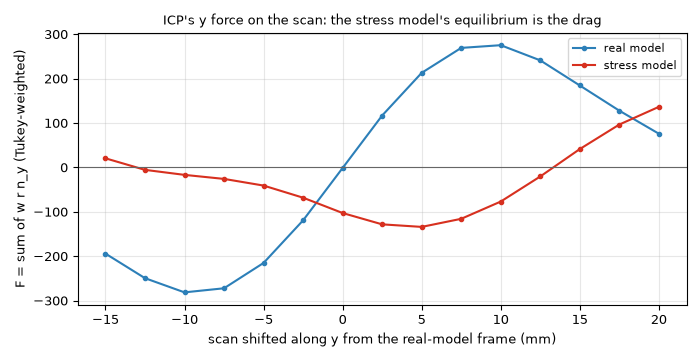

peak RSS so far: 1.47 GB


In [17]:
# Experiment 2: where does the y constraint sit, and why does the 3 cm wall stop resisting? For the scan shifted by dy along y from the real-model frame, each scan point
# is matched to the nearest model triangle; with the Tukey weight w of its point-to-plane residual r (zero beyond 2 cm), the y-gradient of ICP's cost is F(dy) = sum w r n_y
# (zero at an equilibrium; a stable one where F rises through zero) and its stiffness S(dy) = sum w n_y^2 is the y constraint each element carries.
def prep_scene(els):
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))
        first.append(first[-1] + len(e.faces))
    return scene, np.concatenate(normal_list), np.array(first)


def y_constraint(prep, pts, dy):
    scene, normals, first = prep
    q = np.ascontiguousarray(pts + np.array([0, dy / 1000, 0], np.float32), dtype=np.float32)
    r = scene.compute_closest_points(o3d.core.Tensor(q))
    g, foot = r["geometry_ids"].numpy(), r["points"].numpy()
    n = normals[first[g] + r["primitive_ids"].numpy()]
    res = np.einsum("ij,ij->i", q - foot, n)
    w = np.where(np.abs(res) < TUKEY_K, (1 - (res / TUKEY_K) ** 2) ** 2, 0.0) * (np.abs(res) <= ICP_FINE_DIST)
    return g, w * res * n[:, 1], w * n[:, 1] ** 2  # per point: element, its force term, its stiffness term


P_CURVE = P_REAL[::STRIDE]
CURVE, SHARE = {}, {}
for name, els in (("real model", elements), ("stress model", elements_stress)):
    prep = prep_scene(els)
    F, S = [], []
    for dy in DY:
        g, f, s = y_constraint(prep, P_CURVE, dy)
        F.append(f.sum()); S.append(s.sum())
        if dy == 0:
            SHARE[name] = {i: (s[g == i].sum() / s.sum(), f[g == i].sum()) for i in range(len(elements))}
    CURVE[name] = np.array(F)
    roots = [DY[k] - CURVE[name][k] * (DY[k + 1] - DY[k]) / (CURVE[name][k + 1] - CURVE[name][k]) for k in range(len(DY) - 1) if CURVE[name][k] < 0 <= CURVE[name][k + 1]]
    print(f"{name}: stable equilibrium (F rises through zero) at dy = {', '.join(f'{r:.1f}' for r in roots)} mm from the real-model frame")
del prep
print(f"\nat dy = 0 (the real-model frame): share of the y constraint (sum of w n_y^2) per element, and its force (sum of w r n_y; the total is what ICP removes by moving)")
print(f"{'element':28s}{'real model':>16s}{'stress model':>18s}")
shown = sorted({i for k in SHARE for i, (sh, _) in SHARE[k].items() if sh > 0.02} | set(stress_idx))
for i in shown:
    print(f"{short(i):28s}" + "".join(f"{SHARE[k][i][0]:9.1%} {SHARE[k][i][1]:+7.0f}" + (" " * 2 if k == "real model" else "") for k in SHARE) + ("   <- moved " + f"{np.linalg.norm(VEC[i]) * 100:.0f} cm" if i in stress_idx else ""))
print(f"{'the three moved walls together':28s}" + "".join(f"{sum(SHARE[k][i][0] for i in stress_idx):9.1%} {sum(SHARE[k][i][1] for i in stress_idx):+7.0f}  " for k in SHARE))
print(f"{'all elements':28s}" + "".join(f"{sum(v[0] for v in SHARE[k].values()):9.1%} {sum(v[1] for v in SHARE[k].values()):+7.0f}  " for k in SHARE))

fig, ax = plt.subplots(figsize=(7, 3.6))
for k, c in (("real model", "#2c7fb8"), ("stress model", "#d7301f")):
    ax.plot(DY, CURVE[k], "-o", ms=3, color=c, label=k)
ax.axhline(0, color="0.4", lw=0.8)
ax.set_xlabel("scan shifted along y from the real-model frame (mm)"); ax.set_ylabel("F = sum of w r n_y (Tukey-weighted)")
ax.set_title("ICP's y force on the scan: the stress model's equilibrium is the drag", fontsize=9)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(OUT / "icp_pull_y_force.png", dpi=100)
plt.close(fig)
display(Image(filename=str(OUT / "icp_pull_y_force.png"), width=700))
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")


In [18]:
# The new design's moves in a frame refined against their own perturbed model (what a real pipeline would have got): the drag per move, and the verdicts it would give (context)
t = time.time()
DRAG_MOVE, RUNS_DRAG = {}, {}
for mv in MOVES:
    els = ELEMENTS_MOVE[mv["key"]]
    target, _ = icp_target(els)
    T = icp_mode(src_sub, target, "both")
    DRAG_MOVE[mv["key"]] = displacement(T) - EXP[("real model", "both")]
    RUNS_DRAG[mv["key"]] = rows_for(els, assign(els, apply(T, P_REC)), use_all)
    print(f"{mv['key']:14s}: the refinement against its perturbed model differs from the real model's by (x, y, z) {DRAG_MOVE[mv['key']].round(1)} mm, room centroid (every {STRIDE}th scan point)")
del target
print(f"({time.time() - t:.0f} s)")


move_1cm_away : the refinement against its perturbed model differs from the real model's by (x, y, z) [-0.   5.2 -0. ] mm, room centroid (every 8th scan point)


move_3cm_in   : the refinement against its perturbed model differs from the real model's by (x, y, z) [-0.1  3.7 -0. ] mm, room centroid (every 8th scan point)


move_10cm_in  : the refinement against its perturbed model differs from the real model's by (x, y, z) [-0.1  1.  -0. ] mm, room centroid (every 8th scan point)
(31 s)


## 7. Scores

Scoring is absolute and per run: the expected verdict is the manifest's (moves: from the plane arithmetic of section 3; deletions: not confirmed, since missing and not visible need scanner positions and 01 recovered none). Untouched elements have no expected verdict; they are scored only for the false-flag rate. `actual` is the run in the **frozen real-model frame** (section 4); `dragged` is the context run in the frame refined against the move's own perturbed model (section 6). `pure shift` is what the unchanged logic gives on the baseline's own offsets shifted by the injected change (section 3); `fair test` says whether that equals the expected verdict. `read` is whether the wall's median offset changed by the injected amount to `MEDIAN_ERR`.

**Sign convention.** The signed offset is the scan relative to the model, positive towards the room. A model wall moved *into* the room by d reads the scan **behind** the modelled face: the median offset changes by **-d**; moved away by d, by **+d**. The injected change is printed next to the measured median change.

**False-flag rate on untouched elements** (the 05 gate's input: "at most 10 % of untouched elements are falsely flagged shifted or missing"): **the gate number is the absolute count**, per run, over the 34 untouched elements: those whose perturbed-run verdict is shifted or missing, divided by 34. The **new** count (only those not already shifted in the baseline on the real model) is context, not the gate. Missing never occurs here. The collateral lines say what the move did to the windows the wall hosts.


In [19]:
SCORES = {"oracle_labels": [], "no_labels": []}
MOVE_OF = {mv["key"]: mv for mv in MOVES}
for variant in SCORES:
    for key in RUN_ORDER:
        c = CHANGE_OF[key]
        mv = MOVE_OF.get(key)
        for k, (base, run) in enumerate(zip(BASE[variant], RUNS[key]["rows"][variant])):
            g = run["global_id"]
            assert base["global_id"] == g
            is_changed = g == c["global_id"]
            drag = RUNS_DRAG[key][variant][k]["verdict"] if key in RUNS_DRAG else ""
            row = dict(run=key, global_id=g, ifc_class=run["ifc_class"], name=run["name"], change=c["change"] if is_changed else "",
                       injected_change_mm=round(mv["change_mm"], 1) if mv and is_changed else "",
                       expected=c["expected_verdict"] if is_changed else "", actual=run["verdict"], baseline=base["verdict"],
                       predicted_by_pure_shift=PRED[(variant, key)] if mv and is_changed else "",
                       fair_verdict_test=("yes" if TESTABLE[(variant, key)] else "no") if mv and is_changed else "",
                       point_count=run["point_count"], baseline_point_count=base["point_count"], median_signed_offset_mm=run["median_mm"], baseline_median_mm=base["median_mm"],
                       median_change_mm=run["median_mm"] - base["median_mm"], share_within_tol=run["share_within_tol"], baseline_share_within_tol=base["share_within_tol"],
                       share_near_median=run["share_near_median"], baseline_share_near_median=base["share_near_median"], reason=run["reason"],
                       correct=(run["verdict"] == c["expected_verdict"]) if is_changed else "", actual_dragged_frame=drag)
            row["median_read"] = (abs(row["median_change_mm"] - mv["change_mm"]) <= MEDIAN_ERR * 1000) if mv and is_changed else ""
            SCORES[variant].append(row)

for variant in SCORES:
    print(f"\n=== {variant}: the six changes (expected vs actual; baseline = the real model's verdict of the same element) ===")
    print(f"{'run':15s}{'element':26s}{'expected':>14s}{'actual':>14s}{'baseline':>14s}{'pure shift':>14s}{'fair test':>10s}{'points':>9s}{'(base)':>9s}{'median chg':>11s}{'injected':>9s}{'read':>5s}{'in tol':>8s}{'cluster':>8s}{'(base)':>8s}{'dragged':>14s}  ok  reason")
    for r in (r for r in SCORES[variant] if r["change"]):
        print(f"{r['run']:15s}{(r['ifc_class'][3:12] + ' ' + r['name'][-10:]):26s}{r['expected']:>14s}{r['actual']:>14s}{r['baseline']:>14s}{r['predicted_by_pure_shift']:>14s}{r['fair_verdict_test']:>10s}"
              f"{r['point_count']:9,d}{r['baseline_point_count']:9,d}{r['median_change_mm']:9.1f}mm{str(r['injected_change_mm']):>9s}{('yes' if r['median_read'] else 'NO') if r['median_read'] != '' else '':>5s}{r['share_within_tol']:8.1%}{r['share_near_median']:8.1%}{r['baseline_share_near_median']:8.1%}"
              f"{r['actual_dragged_frame']:>14s}  {'yes' if r['correct'] else 'NO '}  {r['reason']}")
    perturbed = [r for r in SCORES[variant] if r["change"]]
    moves = [r for r in perturbed if r["change"] == "moved"]
    print(f"verdict as expected: {sum(r['correct'] for r in perturbed)} of {len(perturbed)}; of the 3 moves {sum(r['correct'] for r in moves)} (fair verdict tests: {sum(r['fair_verdict_test'] == 'yes' for r in moves)}, "
          f"and right in {sum(r['correct'] for r in moves if r['fair_verdict_test'] == 'yes')} of them); median change read to {MEDIAN_ERR * 1000:.0f} mm: {sum(r['median_read'] for r in moves)} of 3; "
          f"deletions as expected: {sum(r['correct'] for r in perturbed if r['change'] == 'not_built')} of 3")

    print(f"\nfalse flags and collateral, {variant}, per run (untouched = the other 34 elements; the gate counts shifted or missing, absolute):")
    for key in RUN_ORDER:
        rows = [r for r in SCORES[variant] if r["run"] == key and not r["change"]]
        flagged = [r for r in rows if r["actual"] in ("shifted", "missing")]
        new = [r for r in flagged if r["baseline"] != "shifted"]
        differs = [r for r in rows if r["actual"] != r["baseline"]]
        print(f"  {key:15s} flagged shifted or missing {len(flagged)} of {len(rows)} ({len(flagged) / len(rows):.1%}), of which new {len(new)}; verdict differs from the baseline: {len(differs)}"
              + "".join(f"\n      flagged: {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {r['actual']} (baseline {r['baseline']}, median {r['median_signed_offset_mm']:.1f} mm)" for r in flagged)
              + "".join(f"\n      {r['ifc_class'][3:]:18s} {r['name'][-24:]:26s} {r['baseline']} -> {r['actual']}" for r in differs))
    win = [g for g, h in HOST.items() if h == GUIDS[MOVED] and META[g]["ifc_class"] == "IfcWindow"]
    win_ok = [g for g in win if BASE[variant][GUIDS.index(g)]["verdict"] == "OK"]
    for mv in MOVES:
        still = [g for g in win_ok if RUNS[mv["key"]]["rows"][variant][GUIDS.index(g)]["verdict"] == "OK"]
        still_d = [g for g in win_ok if RUNS_DRAG[mv["key"]][variant][GUIDS.index(g)]["verdict"] == "OK"]
        print(f"  collateral, {mv['key']:14s}: the wall hosts {len(win)} windows, {len(win_ok)} OK in the baseline; still OK in the frozen frame {len(still)}, in the dragged frame {len(still_d)}; "
              + "; ".join(f"{META[g]['name'][-7:]} {BASE[variant][GUIDS.index(g)]['point_count']:,} -> {RUNS[mv['key']]['rows'][variant][GUIDS.index(g)]['point_count']:,} points, "
                          f"{BASE[variant][GUIDS.index(g)]['share_within_tol']:.1%} -> {RUNS[mv['key']]['rows'][variant][GUIDS.index(g)]['share_within_tol']:.1%} in tol" for g in win_ok))



=== oracle_labels: the six changes (expected vs actual; baseline = the real model's verdict of the same element) ===
run            element                         expected        actual      baseline    pure shift fair test   points   (base) median chg injected read  in tol cluster  (base)       dragged  ok  reason
move_1cm_away  WallStand all:973242                  OK            OK            OK            OK       yes  134,367  134,469     10.0mm     10.0  yes   97.7%   98.3%   98.3%            OK  yes  
move_3cm_in    WallStand all:973242             shifted       shifted            OK       shifted       yes  134,770  134,469    -30.0mm    -30.0  yes    0.7%   98.0%   98.3%       shifted  yes  
move_10cm_in   WallStand all:973242             shifted       shifted            OK       shifted       yes  146,038  134,469    -99.8mm   -100.0  yes    0.2%   97.8%   98.3%       shifted  yes  
delete_door    Door 30:1044681            not confirmed not confirmed not confirmed          

### Why the median of the moved wall follows the injected offset (or not)

The offsets of the moved wall's counted element-class points (percentiles) before and after, in each move's run (frozen frame), with its room-facing sides in the perturbed model (it should stay one: a moved boundary wall must not turn into a partition), how many of its band points the side test left out as the back of the wall, how many the junction margin left out, and how many it could not decide.


In [20]:
print(f"{'run':15s} {'':9s} {'room-facing sides':>18s}   {'offsets of the wall, labels, mm (p10 / p25 / p50 / p75 / p90)':>62s}   {'reference':>9s} {'back of wall':>12s} {'at junction':>11s} {'ambiguous':>9s}")
for mv in MOVES:
    for label, A, els in (("baseline", A_REAL, elements), ("perturbed", RUNS[mv["key"]]["A"], RUNS[mv["key"]]["els"])):
        idx = A.points_of[MOVED]
        pct = np.percentile(A.signed[idx[is_element_class[idx]]] * 1000, [10, 25, 50, 75, 90])
        w = A.walls[MOVED]
        print(f"{mv['key']:15s} {label:9s} {room_sides(els[MOVED]):12d} side(s)   " + " / ".join(f"{v:6.0f}" for v in pct).rjust(62)
              + f"   {('+' if w['ref'] > 0 else '-') + 'xy'[w['axis']]:>9s} {w['n_dropped']:12,d} {A.junction_n[MOVED]:11,d} {w['n_ambiguous'] / w['n_band']:9.0%}")


run                        room-facing sides    offsets of the wall, labels, mm (p10 / p25 / p50 / p75 / p90)   reference back of wall at junction ambiguous
move_1cm_away   baseline             1 side(s)                           -6 /     -5 /     -4 /     -3 /     -2          -y      151,613      35,311        9%
move_1cm_away   perturbed            1 side(s)                            4 /      5 /      6 /      7 /      8          -y      152,493      33,436        8%
move_3cm_in     baseline             1 side(s)                           -6 /     -5 /     -4 /     -3 /     -2          -y      151,613      35,311        9%
move_3cm_in     perturbed            1 side(s)                          -36 /    -35 /    -34 /    -33 /    -32          -y      137,988      37,716       11%
move_10cm_in    baseline             1 side(s)                           -6 /     -5 /     -4 /     -3 /     -2          -y      151,613      35,311        9%
move_10cm_in    perturbed            2 side(s)  

## 8. Outputs

`scores_oracle_labels.csv` and `scores_no_labels.csv`: one row per element per run (6 runs x 35 elements), `run, global_id, ifc_class, name, change, injected_change_mm, expected, actual, baseline, predicted_by_pure_shift, fair_verdict_test, point_count, baseline_point_count, median_signed_offset_mm, baseline_median_mm, median_change_mm, median_read, share_within_tol, baseline_share_within_tol, reason, correct, actual_dragged_frame`. The columns `change`, `injected_change_mm`, `expected`, `predicted_by_pure_shift`, `fair_verdict_test`, `median_read` and `correct` are set only on the run's changed element; `actual` (frozen frame) and `baseline` (real model, 03a's verdict) are always set; `actual_dragged_frame` only on the three move runs. `occlusion_control.csv`: the deleted wall's row in the four configurations of section 4. `manifest.json`: one entry per run, with the perturbed IFC for a move. The figure has the plan (a cut at chest height, z 1.15 m) for both variants and the median change against the injected change.


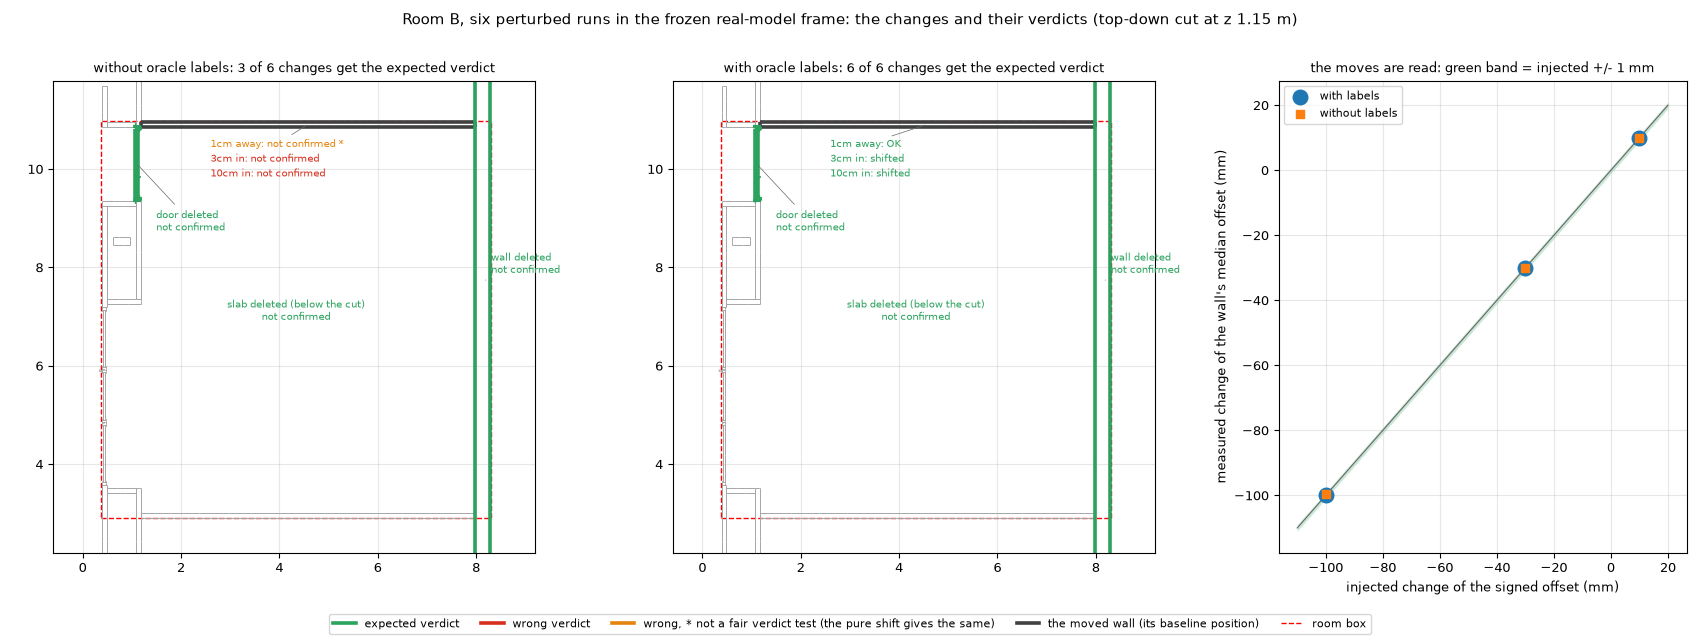

wrote craslabbim_move_10cm_in.ifc craslabbim_move_1cm_away.ifc craslabbim_move_3cm_in.ifc icp_pull_y_force.png manifest.json occlusion_control.csv scores_no_labels.csv scores_oracle_labels.csv scores_top_down.png
peak RSS 1.47 GB, notebook run 481 s


In [21]:
FIELDS = ["run", "global_id", "ifc_class", "name", "change", "injected_change_mm", "expected", "actual", "baseline", "predicted_by_pure_shift", "fair_verdict_test", "point_count",
          "baseline_point_count", "median_signed_offset_mm", "baseline_median_mm", "median_change_mm", "median_read", "share_within_tol", "baseline_share_within_tol", "share_near_median",
          "baseline_share_near_median", "reason", "correct",
          "actual_dragged_frame"]
for variant, rows in SCORES.items():
    with open(OUT / f"scores_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 2) if isinstance(v, float) else v) for k, v in {k: r[k] for k in FIELDS}.items()})
with open(OUT / "occlusion_control.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["wall", "configuration", "variant", "verdict", "reason", "point_count", "median_mm", "share_within_tol", "share_near_median"])
    for (name, variant), r in CONTROL.items():
        w.writerow([META[g_hid]["name"], name, variant, r["verdict"], r["reason"], r["point_count"], round(r["median_mm"], 2), round(r["share_within_tol"], 4), round(r["share_near_median"], 4)])


def section(els, axis, value):
    # Line segments where the plane axis == value cuts the elements' triangles: (n, 2, 2), two end points in the other two axes.
    keep_axes = [i for i in range(3) if i != axis]
    out = []
    for e in els:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep_axes] + t[:, None] * (tri[idx, j][:, keep_axes] - tri[idx, i][:, keep_axes])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


CLASS_WORD = {"IfcDoor": "door", "IfcSlab": "slab", "IfcWallStandardCase": "wall"}  # an unlisted class raises
GREEN, RED, AMBER = "#2ca25f", "#d7301f", "#e6850e"
fig, axs = plt.subplots(1, 3, figsize=(17, 6.4), gridspec_kw=dict(width_ratios=[1, 1, 0.8]))
for ax, (variant, title) in zip(axs[:2], (("no_labels", "without oracle labels"), ("oracle_labels", "with oracle labels"))):
    rows = {r["run"]: r for r in SCORES[variant] if r["change"]}
    ax.add_collection(LineCollection(section(elements, 2, Z_CUT), colors="0.65", linewidths=0.7))
    for k, key in enumerate(RUN_ORDER):
        r, c = rows[key], CHANGE_OF[key]
        e = elements[GUIDS.index(c["global_id"])]
        fair = r["fair_verdict_test"] != "no"
        colour = GREEN if r["correct"] else (RED if fair else AMBER)  # amber: wrong, but the pure shift cannot give the expected verdict either (not a fair verdict test)
        if c["change"] == "not_built":
            cut = section([e], 2, Z_CUT)
            if len(cut):
                ax.add_collection(LineCollection(cut, colors=colour, linewidths=2.6))
                x, y = (e.vertices[:, :2].min(0) + e.vertices[:, :2].max(0)) / 2
                ax.annotate(f"{CLASS_WORD[c['ifc_class']]} deleted\n{r['actual']}", (x, y), xytext=(14, -48) if c["ifc_class"] == "IfcDoor" else (6, 6), textcoords="offset points", fontsize=7,
                            color=colour, arrowprops=dict(arrowstyle="-", lw=0.5, color="0.4"))
            else:  # the floor slab is below the cut: label it in the middle of the room
                ax.text((box_lo[0] + box_hi[0]) / 2, (box_lo[1] + box_hi[1]) / 2, f"{CLASS_WORD[c['ifc_class']]} deleted (below the cut)\n{r['actual']}", fontsize=7, color=colour, ha="center")
        else:
            if k == 0:
                ax.add_collection(LineCollection(section([e], 2, Z_CUT), colors="0.25", linewidths=2.6))
                x, y = (e.vertices[:, :2].min(0) + e.vertices[:, :2].max(0)) / 2
            ax.annotate(f"{key[5:].replace('_', ' ')}: {r['actual']}{'' if fair else ' *'}", (x, y), xytext=(2.6, 10.45 - 0.3 * k), textcoords="data", fontsize=7, color=colour,
                        arrowprops=dict(arrowstyle="-", lw=0.5, color="0.4") if k == 0 else None)
    ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
    ax.set_xlim(-0.6, 9.2); ax.set_ylim(2.2, 11.8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    n_ok = sum(bool(r["correct"]) for r in rows.values())
    ax.set_title(f"{title}: {n_ok} of {len(rows)} changes get the expected verdict", fontsize=9)
ax = axs[2]
ax.plot([-110, 20], [-110, 20], color="0.4", lw=0.8)
ax.fill_between([-110, 20], [-110 - MEDIAN_ERR * 1000, 20 - MEDIAN_ERR * 1000], [-110 + MEDIAN_ERR * 1000, 20 + MEDIAN_ERR * 1000], color=GREEN, alpha=0.25, lw=0)
for variant, marker, label in (("oracle_labels", "o", "with labels"), ("no_labels", "s", "without labels")):
    mrows = [r for r in SCORES[variant] if r["change"] == "moved"]
    ax.scatter([r["injected_change_mm"] for r in mrows], [r["median_change_mm"] for r in mrows], marker=marker, s=110 if variant == "oracle_labels" else 35, label=label, zorder=3)
ax.set_xlabel("injected change of the signed offset (mm)"); ax.set_ylabel("measured change of the wall's median offset (mm)")
ax.set_title(f"the moves are read: green band = injected +/- {MEDIAN_ERR * 1000:.0f} mm", fontsize=9)
ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.legend(handles=[plt.Line2D([], [], color=GREEN, lw=2.6, label="expected verdict"), plt.Line2D([], [], color=RED, lw=2.6, label="wrong verdict"),
                    plt.Line2D([], [], color=AMBER, lw=2.6, label="wrong, * not a fair verdict test (the pure shift gives the same)"), plt.Line2D([], [], color="0.25", lw=2.6, label="the moved wall (its baseline position)"),
                    plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")], loc="lower center", ncol=5, fontsize=8)
fig.suptitle("Room B, six perturbed runs in the frozen real-model frame: the changes and their verdicts (top-down cut at z 1.15 m)")
plt.tight_layout(rect=(0, 0.05, 1, 0.97))
fig.savefig(OUT / "scores_top_down.png", dpi=100)  # 1700 x 640 px
plt.close(fig)
display(Image(filename=str(OUT / "scores_top_down.png"), width=1300))
print("wrote", *sorted(p.name for p in OUT.iterdir()))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")


## Answer

Room B of the CRAS lab, 35 elements, 03a's verdict logic and parameters unchanged (including the wall side test and junction margin of issue #17). The perturbation design was changed in this round of #18, not the logic: **each change is now its own perturbed model and run, the moves are on the one wall that is OK in the baseline, and each move has an expected verdict that is derived and printed before the runs.** Six runs in the real model's frozen frame (every number below is printed by a cell; section numbers in brackets).

**Result in one paragraph.** With oracle labels **all six changes get the verdict they should**: the 1 cm control stays OK, the 3 and 10 cm moves read shifted, the three deletions are not confirmed, and every move is read at its injected size (median change +10.0, -30.0 and -99.8 mm for injected +10, -30 and -100). Without labels **3 of 6**: the three deletions only; the moves are read at the injected size (all three within 1 mm) but none gets its verdict, because no wall is OK without labels and, for the two moves that a pure shift would read as shifted, the one-cluster share falls from 80.5 % to 79.0 and 78.8 %, under the rule's 80 % (below). The false-flag rate is **1 of 34 (2.9 %) in every run, in both variants**, and that wall is `Drywall:9625`, already shifted in the baseline; no run adds a flag.

**Design and why** [section 3].
- *The moved wall.* The first design moved `Drywall:9615` (94.4 % within 15 mm in the baseline, against the 95 % rule) and the partition `9786` (ambiguous side), which cannot show a verdict change. The new rule: inside the room box, one room-facing side (a boundary wall; a partition's two faces make a 10 cm move degenerate), OK in the baseline with labels. **Exactly one wall qualifies, `Drywall:9732`, and no wall is OK without labels** (the table lists all 11 walls). The three moves (1, 3, 10 cm) are three perturbed models, each with its own IFC.
- *What each move should read.* Expected = LOA30 on the true deviation of the wall's plane: the wall's scan plane lies -3.9 mm from the model face (98.9 % of its wall-class points within 15 mm of the plane); after a change the plane lies at -3.9 + change; OK if within 15 mm, shifted if beyond. That gives OK at +6.1 mm for the 1 cm control (moved away from the room), shifted at -33.9 mm (3 cm in) and -103.9 mm (10 cm in).
- *The 1 cm direction, with the arithmetic.* The same offsets through the unchanged `judge`, as a pure shift of the baseline's own offsets: **1 cm away: +6.1 mm median, 97.7 % within 15 mm: OK. 1 cm into the room (the first design's direction): -13.9 mm, 73.6 % (63.8 % without labels): not confirmed**, i.e. the plane would sit 1.1 mm inside the tolerance edge, where the scatter of the points around it (a few millimetres) leaves a quarter of them outside, and neither OK nor shifted can be said. So "1 cm stays OK" cannot hold for that direction for any wall this tight, and the control was moved the other way, chosen by this arithmetic before any perturbed run. This is an easier control than the roadmap's wording (a deviation well inside the tolerance, not one at its edge); I did not try other walls or rooms.
- *Fair test.* A move is a fair verdict test for a variant only if the pure shift gives the expected verdict. With labels all three are (asserted). Without labels: the 1 cm control is not (the baseline wall is 81.1 % within 15 mm, so the pure shift gives 77.8 %: not confirmed), 3 cm and 10 cm are (shifted, with one cluster holding 80.5 % of the points against the rule's 80 %).
- *Other clean-plane walls* (section 3's table: `Drywall:9625` at -135.5 mm, `9767` at -140.8, `9790` at +48.9): already displaced, so a move can only be scored by its median change, which the moved wall's runs already give in both variants; not used.
- *Deletions* are unchanged from the previous round (door, floor slab `Slab 911079`, wall `919433`; rules and numbers in section 3), each now its own run on the unchanged model. The stress model of the leak and pull sections keeps the first version's three moved walls (the deleted elements are chosen to coexist with them).
- *Pre-registration.* The moved-wall rule, the expected verdicts and the 1 cm direction were written before the perturbed verdicts existed (they use baseline data only). The first design's moved-wall rule was replaced after its results were seen, because those results showed it could not test verdict changes.

**Scores, frozen frame** [section 7] (expected -> actual; fair test = the pure shift gives the expected verdict):

| run | expected | with labels | without labels |
|---|---|---|---|
| move 1 cm away | OK | **OK** (97.7 % in tol; fair) | not confirmed (79.0 %; not a fair test) |
| move 3 cm in | shifted | **shifted** (0.7 %; fair) | not confirmed (4.4 %; fair test, wrong) |
| move 10 cm in | shifted | **shifted** (0.2 %; fair) | not confirmed (3.1 %; fair test, wrong) |
| door deleted | not confirmed | **right** (0 points left, too few) | **right** (4,171 left, inconsistent) |
| slab deleted (OK with labels) | not confirmed | **right** (0 left; was OK) | **right** (102,066 left) |
| wall `919433` deleted | not confirmed | **right** (0 left) | **right** (6,514 left) |

Verdict as expected: 6 of 6 with labels, 3 of 6 without (moves 0 of 3; of the 2 fair verdict tests 0 of 2); median change read to 1 mm: 3 of 3 in both variants. The dragged-frame column (context) gives the same verdicts for the three moves in both variants.

**What the moves show with labels.** The wall's offsets move as injected (p10 to p90: -6 to -2 mm in the baseline; +4 to +8, -36 to -32 and -106 to -100 mm after 1 cm away, 3 cm in and 10 cm in), one cluster each (98.0 % and 97.8 % within 15 mm of the median for 3 and 10 cm). Two things that are not clean: (i) **at 10 cm the moved wall has two room-facing sides in the perturbed model** (printed: 2 side(s); it has 1 at 1 and 3 cm): the moved wall's far face now lies where the box probe sees it as room-facing, so the side test drops no back-of-wall points and counts 146,038 points (134,770 at 3 cm), folding them onto the same offset because the move equals the wall thickness. The reading is right (-99.8 mm) but it is a coincidence of that thickness, not the one-sided case the design meant; the median is the robust part, the 10 cm verdict inherits that. (ii) The two windows that are OK in the baseline and hosted by this wall (`1472119`, `1472259`, 5 hosted in all) stay OK at 1 and 3 cm and **not at 10 cm**: their counted points go from 6,506 / 6,457 to 10,782 / 10,491 and the share within 15 mm from 95.7 / 96.3 % to 78.3 / 91.0 % (the dragged frame gives the same). I did not trace which points enter. At 3 cm with labels, window `1471857` changes from not confirmed to OK; not traced.

**What without labels can and cannot show.** It can show that the offset measurement follows the move (3 of 3 within 1 mm: change +10.0, -30.0, -99.4 against +10, -30, -100). It cannot show the verdicts. No wall is OK without labels, so "OK, then shifted" is untestable and the 1 cm control cannot stay OK (not a fair test). For 3 and 10 cm the pure shift gives shifted, but only just: one cluster holds 80.5 % of the baseline's points against the 80 % line, and the real runs have 79.0 % and 78.8 %. The counted points rise (174,061 in the baseline, 177,525 at 3 cm, 200,022 at 10 cm) and the cluster share falls by 1.5 and 1.7 points. At 3 cm the labelled count rises by only 301 points (134,469 to 134,770), so the 3,464 added without labels are almost all clutter and unassigned points that the moved face brings into the 10 cm band; at 10 cm part of the rise is the folded back face (above), and I did not separate the two. That is not tuned away (the 80 % is a judgement call of 03a); it says that without labels these two verdict tests sit within two points of the rule and the clutter decides them. It is also the size of the gap that learned segmentation would close.

**The occlusion control** [section 4]. Clutter-class scan points in front of the deleted wall `919433` (3 cm to 1 m along its normal): 155,465, covering 36.5 % of its face-area samples (the section 3 voxel measure says 28.7 %); only 2,886 of them (1.9 %) lie within `BAND` of the wall, and the rest never enter the comparison. Without labels: **deleted, clutter stays: 6,514 points left, not confirmed (inconsistent offsets); deleted, clutter in front also removed: 4,249 left, not confirmed (inconsistent offsets)**; with labels both are 0 points, not confirmed (too few). The 2,265 removed are 35 % of the leftover; the rest is 3,313 unassigned and 936 other clutter-class points, which the control (clutter-class in front only, as specified) does not remove. For the wall present (not deleted): 85.9 % within 15 mm, 87.3 % with the clutter in front removed (89.3 % with labels either way): not confirmed in both. **So the measured occlusion has no verdict effect on this wall**: neither the deleted nor the present wall changes verdict, and the points move by a few percent at most, because the clutter in front is almost all beyond the band (98.1 %). The deletion test for this wall therefore shows what it showed before: leftover points do not turn into an OK or shifted verdict; it does not show that occlusion could mislead a verdict, and a wall with more clutter inside the band might. I did not look for one.

**Collateral and false flags** [section 7]. Per run, untouched elements flagged shifted or missing: 1 of 34 (2.9 %) in all six runs and both variants, `Drywall:9625` (shifted at about -135 mm in the baseline already; new flags 0). Untouched elements whose verdict changes against the baseline: none in the 1 cm and the deletion runs and, without labels, the 3 cm run; with labels window `1471857` (3 cm; not confirmed -> OK) and, in both variants, windows `1472119` and `1472259` at 10 cm (OK -> not confirmed). The previous design's collateral (5 windows OK -> not confirmed) was the frame drag, as reported; the new per-move drags (section 6) are +5.2, +3.7 and +1.0 mm along y for 1 cm away, 3 cm in and 10 cm in, much less than the stress model's 13.2 mm, and do not change the moves' verdicts; without labels the 3 cm move in the dragged frame keeps 1 of the 2 OK windows.

**The mask leak and the ICP pull, unchanged findings on the stress model** [sections 5 and 6]. Leak (stress model, frozen frame; element-class points on a deleted element that the mask did not take): door 430 -> 0, slab 508 -> 0, wall `919433` 0 -> 0 with the geometric mask against the assignment-based mask; in the dragged frame 2,769 -> 0, 598 -> 0, 57 -> 57 (points outside the band that the 13 mm drift brings in). The geometric mask also removes points of other elements (door 16,875, slab 24,640, wall `919433` 31,825). ICP against the stress model displaces the frame by 13.2 mm along y; the single-wall and pair runs (every 8th point; difference to the real model with the same pass, mm): 1 cm wall +0.7 Tukey / +3.4 plain, 3 cm +3.7 / -16.5, 10 cm 0.0 / +2.6, 1 cm + 3 cm +13.2 / -12.5, all three +13.2 / -12.4 (both passes: +13.2). In the real-model frame the 1 cm and 3 cm walls carry 39.5 % and 48.4 % of the Tukey-weighted y constraint (the three together 88.0 %); after the moves the 3 cm wall carries 7.6 % (not zero) with its force from +98 to 0, and the 1 cm wall (46.6 %) is unopposed. What the data show: the 1 cm wall alone moves the frame 0.7 mm (the opposite wall holds it), the pair 13.2, so the pull is not additive; the plain pass also moves the frame, the other way; I did not test why, a larger kernel or other rooms. The geometric masks, if also left out of the ICP input, move the frame 35.7 mm in x and 5.4 mm in z. Freezing the transform avoids all of it for this test.

**What it says about the 05 gate** ("every injected change beyond tolerance gets the right verdict, and at most 10 % of untouched elements are falsely flagged shifted or missing"). Second clause: passes (2.9 % per run). First clause: **with labels it passes** (3 cm and 10 cm shifted, the control OK, the deletions not confirmed), on one wall of one room and with a control that is far inside the tolerance rather than at its edge; **without labels it fails** (0 of the 2 beyond-tolerance moves get shifted, and the margin is two points of an 80 % judgement call). I would not call the without-labels failure a defect of the perturbation design: the design's expected verdicts hold for a perfect measurement with the labels' points, and it is the clutter that decides them without.

**Not checked / doubts.** The "fair test" definition and `MEDIAN_ERR` (1 mm) are my judgement calls. All three moves are on one wall in one room (the only OK wall), so nothing here says how the logic does on other walls; a quieter-versus-noisier wall comparison would need another room. The 10 cm run is partly degenerate (two sides, folded back face). Collateral windows at 10 cm and window `1471857` at 3 cm are not traced. The control for the occlusion removes clutter-class points only. ICP experiment 2 is a one-dimensional approximation, not ICP, and experiment 1 uses every 8th point (it reproduces the full-scan 13.2 mm). nbclient's timeout is per cell, not for the notebook; the test runs it with 3,600 s per cell, and the notebook prints its own total run time on its last line.
